# 7.2(d) Seaborn

Seaborn is a statistical data visualization library built on top of Matplotlib. It provides a high-level interface for exploring relationships, comparing groups, visualizing distributions, and presenting statistical summaries. Seaborn works especially well with Pandas DataFrames.

**Important Point:** Seaborn creates plots using Matplotlib.
You can customize a Seaborn plot with Matplotlib methods such as
`ax.set_title()`, `ax.set_xlabel()`, `fig.tight_layout()`, and `fig.savefig()`.

## Installation and Imports

Install Seaborn and its common dependencies:

In [1]:
# Install ALL dependencies used in this notebook (runs once per kernel):
%pip install seaborn matplotlib pandas numpy scipy statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.3 MB 2.1 MB/s eta 0:00:06
   --- ------------------------------------ 1.0/11.3 MB 2.1 MB/s eta 0:00:05
   ---- ----------------------------------- 1.3/11.3 MB 1.6 MB/s eta 0:00:07
   ----- ---------------------------------- 1.6/11.3 MB 1.6 MB/s eta 0:00:07
   ------ --------------------------------- 1.8/11.3 MB 1.6 MB/s eta 0:00:06
   -------- ------------------------------- 2.4/11.3 MB 1.8 MB/s eta 0:00:06
   ---------- ----------------------------- 2.9/11.3 MB 1.8 MB/s eta 0:00:05
   ------------ --------------------------- 3.4/11.3 MB 1.9 MB/s eta 0:00:05
   ------------- -------------------------- 3.9/11.3 MB 2.0 MB/s eta 0:00:04
   ---------------- ----------------------- 4.7/11.3 MB 2.1 MB/s eta 0:00:04
   ------------------ --------------------- 5.2/11.3 MB 2.1 MB/s eta 0:00:03
   ----------

Import the libraries:

In [2]:
# Import seaborn for statistical visualization
import seaborn as sns

# Import matplotlib.pyplot for figure customization
import matplotlib.pyplot as plt

# Import pandas for DataFrames
import pandas as pd

# Import numpy for numerical operations
import numpy as np

Check the installed Seaborn version:

In [3]:
# Print the installed seaborn version
print(sns.__version__)

0.13.2


Load a built-in example dataset:

In [4]:
# Load the built-in restaurant tips dataset (needs internet the first time)
tips = sns.load_dataset("tips")

# Print the first 5 rows
print(tips.head())

# Print column info: data types, non-null counts, memory usage
print(tips.info())

# Print summary statistics of the numeric columns
print(tips.describe())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB
None
       total_bill         tip        size
count  244.000000  244.000000  244.000000
mean    19.785943    2.998279    2.569672
std      8.

Built-in datasets are useful for practice. They may require an internet
connection the first time they are downloaded.

## Seaborn Fundamentals

Most Seaborn functions accept data in **long-form** format: each row is
an observation, and each column is a variable.

Example:

In [5]:
# Build a small long-form DataFrame: each row is one observation
df = pd.DataFrame({
    "day": ["Mon", "Tue", "Wed", "Mon", "Tue", "Wed"],
    "group": ["A", "A", "A", "B", "B", "B"],
    "sales": [20, 25, 22, 30, 28, 35],
    "customers": [10, 12, 11, 15, 14, 18]
})

# Show the DataFrame
print(df)

   day group  sales  customers
0  Mon     A     20         10
1  Tue     A     25         12
2  Wed     A     22         11
3  Mon     B     30         15
4  Tue     B     28         14
5  Wed     B     35         18


### Common parameters

- `data`: DataFrame or other data source.
- `x`, `y`: Variables mapped to the horizontal and vertical axes.
- `hue`: Variable mapped to color.
- `style`: Variable mapped to marker or line style.
- `size`: Variable mapped to marker size.
- `col`, `row`: Variables used to create subplot facets.
- `palette`: Color palette.
- `kind`: Plot type used by figure-level functions.
- `ax`: Existing Matplotlib Axes for axes-level functions.
- `height`, `aspect`: Size of each facet for figure-level functions.
- `order`, `hue_order`: Explicit category ordering.
- `errorbar`: Controls uncertainty intervals in supported functions.

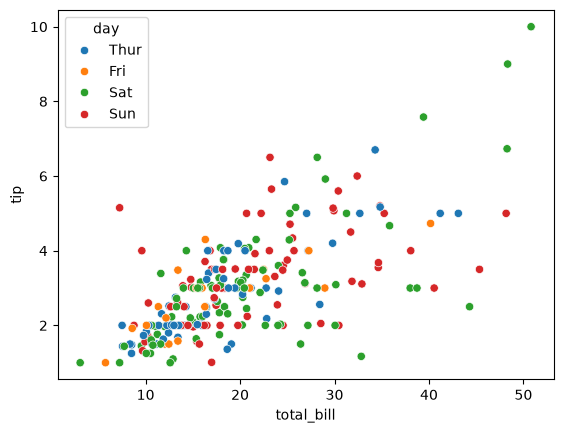

In [6]:
# Scatter plot of total_bill vs tip, colored by day
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="day")

# Display the figure
plt.show()

---

## Axes-Level vs Figure-Level Functions

### Axes-level functions

These draw into a single Matplotlib axes and usually return an `Axes`
object.

Examples: `sns.scatterplot()`, `sns.histplot()`, `sns.boxplot()`,
`sns.heatmap()`.

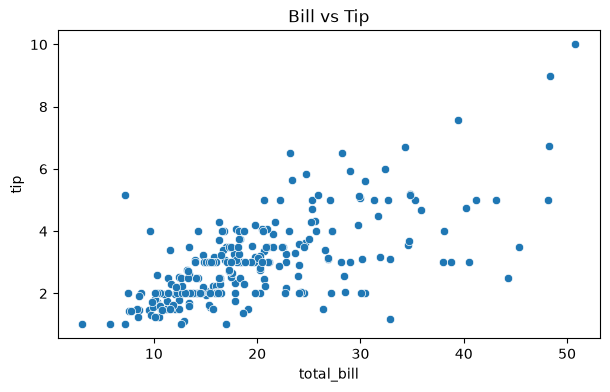

In [7]:
# Create a 7x4 inch figure with one axes
fig, ax = plt.subplots(figsize=(7, 4))

# Draw the scatter plot into the existing axes
sns.scatterplot(data=tips, x="total_bill", y="tip", ax=ax)

# Set the title using a Matplotlib method
ax.set_title("Bill vs Tip")

# Display the figure
plt.show()

### Figure-level functions

These manage a figure and may create multiple subplots. They often
return a Seaborn grid object.

Examples: `sns.relplot()`, `sns.displot()`, `sns.catplot()`,
`sns.lmplot()`, `sns.pairplot()`, `sns.jointplot()`.

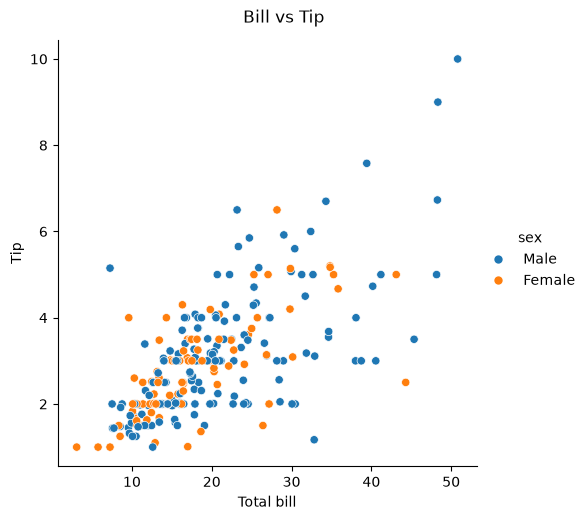

In [8]:
# Figure-level relational plot, colored by sex; returns a FacetGrid
g = sns.relplot(data=tips, x="total_bill", y="tip", hue="sex")

# Set axis labels using the grid's own method
g.set_axis_labels("Total bill", "Tip")

# Add a figure title slightly above the plot (y=1.03)
g.fig.suptitle("Bill vs Tip", y=1.03)

# Display the figure
plt.show()

**Remember:** Figure-level functions manage their own figure. Use grid
methods such as `g.set_axis_labels()` and `g.fig.suptitle()` to
customize them.

## Themes and Styling

Set a theme:

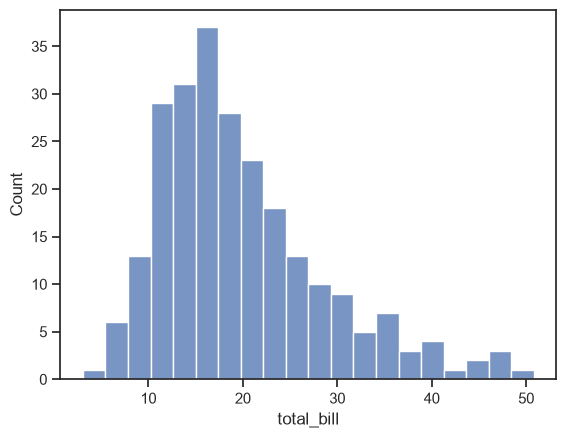

In [9]:
# Apply the default seaborn theme
sns.set_theme()

# White background with a light grid
sns.set_theme(style="whitegrid")

# Dark background with a grid
sns.set_theme(style="darkgrid")

# Plain white background
sns.set_theme(style="white")

# Plain dark background
sns.set_theme(style="dark")

# White background with emphasized axis ticks
sns.set_theme(style="ticks")

# Quick demo plot showing the final applied theme
sns.histplot(data=tips, x="total_bill", bins=20)

# Display the figure
plt.show()

Control context and font scaling:

In [10]:
# Set notebook context with slightly larger fonts
sns.set_theme(context="notebook", font_scale=1.1)

# Compact figures (for papers)
sns.set_context("paper")

# Default notebook display
sns.set_context("notebook")

# Larger text for presentations
sns.set_context("talk")

# Very large text for posters
sns.set_context("poster")

# Restore the default notebook context
sns.set_context("notebook")

Temporarily apply a theme:

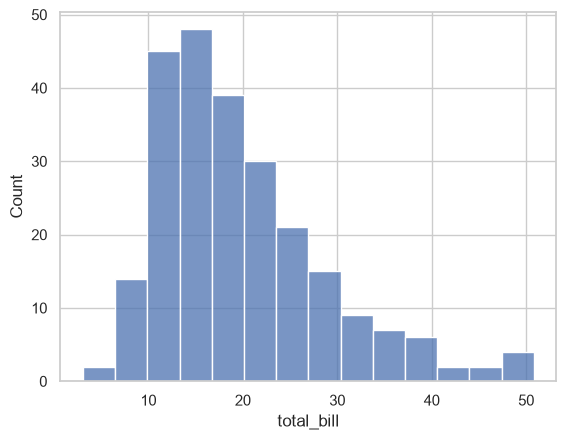

In [11]:
# Use the whitegrid style only inside this with-block
with sns.axes_style("whitegrid"):

    # Create a figure and axes inside the temporary style
    fig, ax = plt.subplots()

    # Draw a histogram into the axes
    sns.histplot(data=tips, x="total_bill", ax=ax)

    # Display the figure
    plt.show()

Choose styling that improves readability. Avoid using a theme simply
because it looks attractive if it makes comparisons harder.

## Color Palettes

View palettes:

In [ ]:
# Show the default color palette
sns.color_palette()

# General-purpose categorical colors
sns.color_palette("deep")

# Muted categorical colors
sns.color_palette("muted")

# Soft pastel colors
sns.color_palette("pastel")

# Bright categorical colors
sns.color_palette("bright")

# Dark categorical colors
sns.color_palette("dark")

# Palette designed to be distinguishable for colorblind viewers
sns.color_palette("colorblind")

[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

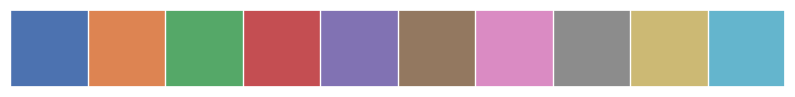

In [13]:
# Visualize the "deep" palette as a strip of colors
sns.palplot(sns.color_palette("deep"))

# Display the figure
plt.show()

Use a palette for a plot:

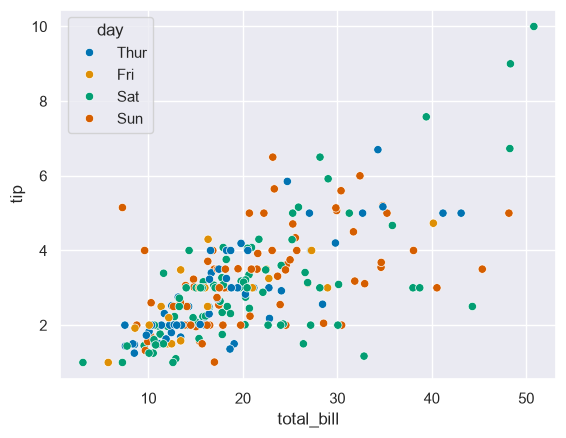

In [14]:
# Scatter plot colored by day using the colorblind-safe palette
sns.scatterplot(data=tips, x="total_bill", y="tip",
                hue="day", palette="colorblind")

# Display the figure
plt.show()

Set a default palette:

In [15]:
# Set "deep" as the default palette for all following plots
sns.set_palette("deep")

Create a sequential palette:

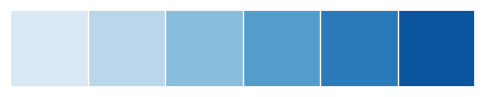

In [16]:
# Sequential Blues palette with 6 colors
sns.color_palette("Blues", n_colors=6)

# Sequential viridis palette with 6 colors
sns.color_palette("viridis", n_colors=6)

# Visualize the 6-color Blues palette
sns.palplot(sns.color_palette("Blues", n_colors=6))

# Display the figure
plt.show()

Create a diverging palette:

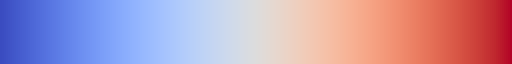

In [17]:
# Diverging vlag palette returned as a colormap object
sns.color_palette("vlag", as_cmap=True)

# Diverging coolwarm palette returned as a colormap object
sns.color_palette("coolwarm", as_cmap=True)

Custom colors:

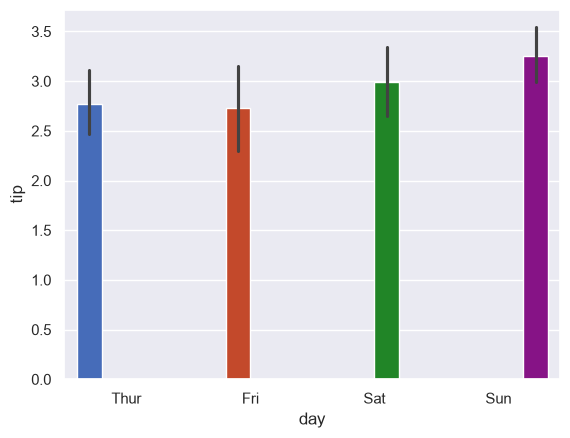

In [18]:
# Define four custom hex colors (one per day category: Thur, Fri, Sat, Sun)
custom_palette = ["#3366CC", "#DC3912", "#109618", "#990099"]

# Bar plot using the custom palette, colored by day, no legend
sns.barplot(data=tips, x="day", y="tip", palette=custom_palette, hue="day", legend=False)

# Display the figure
plt.show()

Use categorical palettes for categories, sequential palettes for ordered
magnitude, and diverging palettes when values vary around a meaningful
center.

## Relational Plots

Relational plots help explore relationships between variables.

### Scatter plot

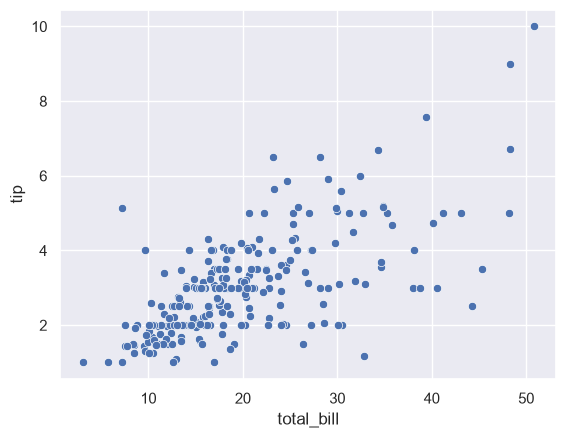

In [19]:
# Scatter plot of total_bill vs tip
sns.scatterplot(data=tips, x="total_bill", y="tip")

# Display the figure
plt.show()

Map more variables to visual features:

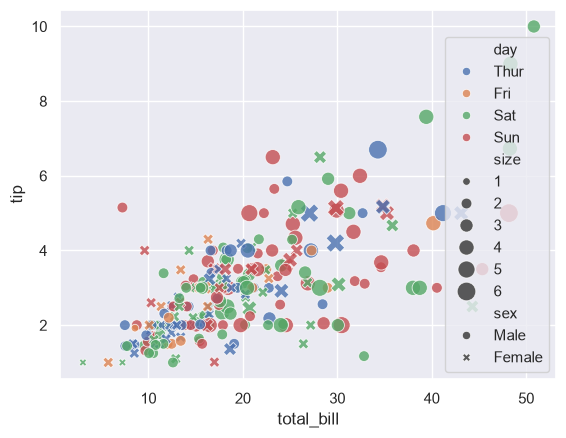

In [20]:
# Scatter plot mapping several variables to visual features
sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="day",                 # Color by day
    style="sex",               # Marker style by sex
    size="size",               # Marker size by party size
    sizes=(30, 180),
    alpha=0.8
)

# Display the figure
plt.show()

Useful parameters: `hue`, `style`, `size`, `sizes`, `alpha`, `palette`,
`legend`, `markers`, `hue_order`.

### Line plot

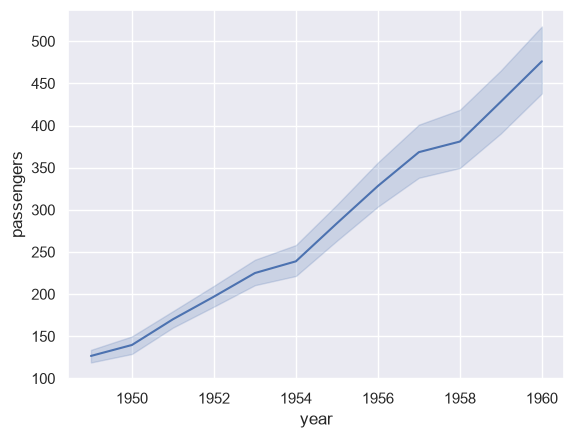

In [21]:
# Load the built-in flights dataset (monthly passenger counts)
flights = sns.load_dataset("flights")

# Line plot of passengers over the years
sns.lineplot(data=flights, x="year", y="passengers")

# Display the figure
plt.show()

When multiple observations share an x-value, `lineplot()` can aggregate
them and display an uncertainty interval by default. To show a line
without an uncertainty interval:

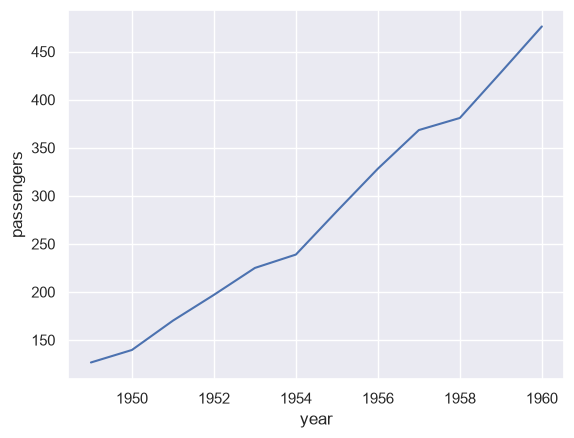

In [22]:
# Line plot with no uncertainty interval (errorbar=None)
sns.lineplot(data=flights, x="year", y="passengers", errorbar=None)

# Display the figure
plt.show()

Multiple lines:

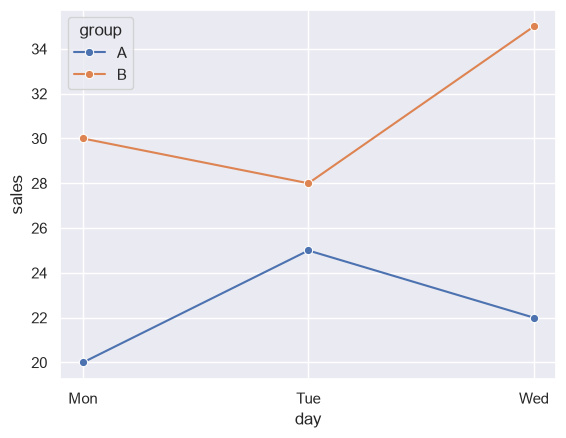

In [23]:
# Small sales DataFrame with two groups
df = pd.DataFrame({
    "day": ["Mon", "Tue", "Wed", "Mon", "Tue", "Wed"],
    "group": ["A", "A", "A", "B", "B", "B"],
    "sales": [20, 25, 22, 30, 28, 35],
    "customers": [10, 12, 11, 15, 14, 18]
})

# Line plot with one line per group and circle markers
sns.lineplot(data=df, x="day", y="sales", hue="group", marker="o")

# Display the figure
plt.show()

For ordered dates or time values, make sure the x variable is correctly
typed and sorted.

### Figure-level relational plot

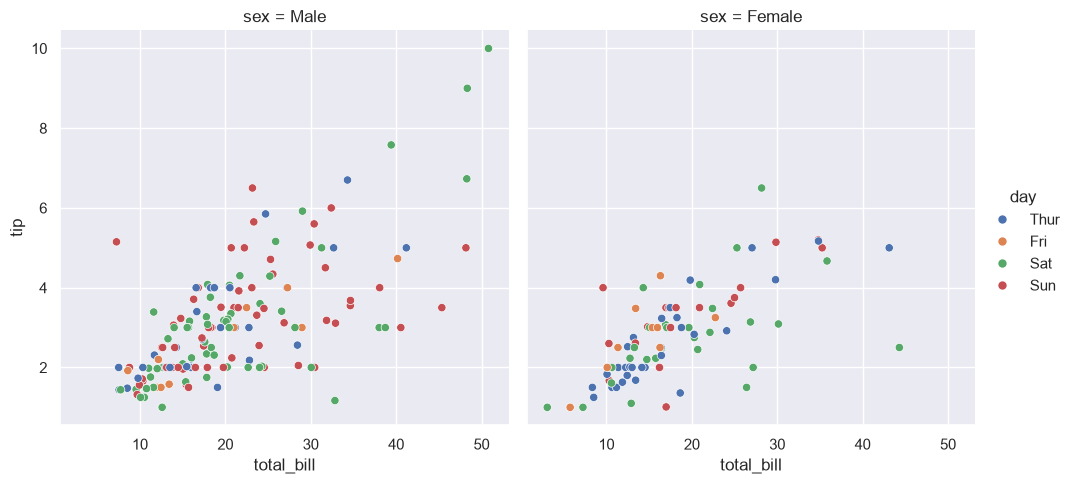

In [24]:
# Figure-level scatter plot, faceted into columns by sex
sns.relplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="day",
    col="sex",
    kind="scatter"
)

# Display the figure
plt.show()

Switch to a line plot:

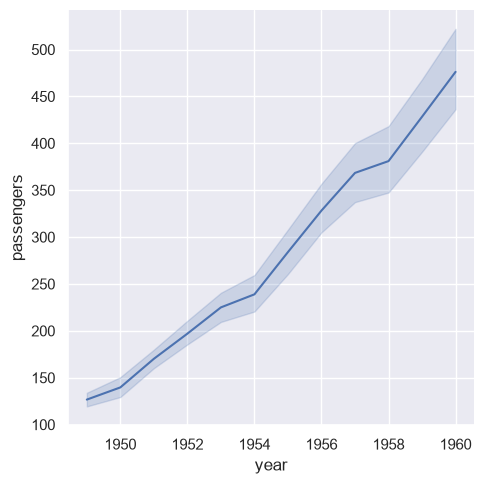

In [25]:
# Figure-level line plot of the flights data
sns.relplot(data=flights, x="year", y="passengers", kind="line")

# Display the figure
plt.show()

## Distribution Plots

Distribution plots show how numerical values are spread.

### Histogram

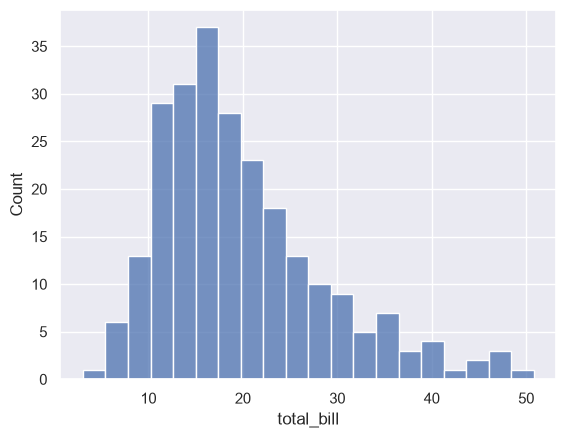

In [26]:
# Histogram of total_bill with 20 bins
sns.histplot(data=tips, x="total_bill", bins=20)

# Display the figure
plt.show()

Common options:

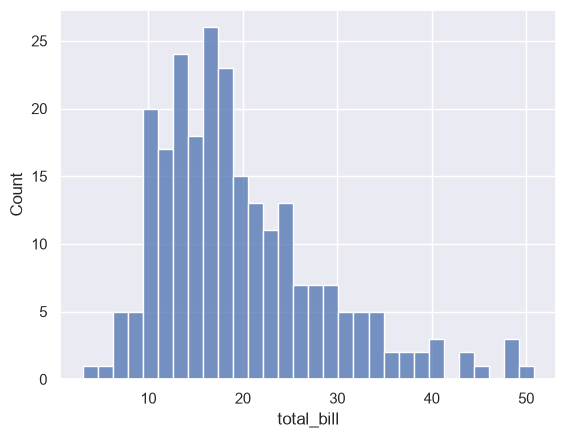

In [27]:
# Histogram with 30 bins
sns.histplot(data=tips, x="total_bill", bins=30)

# Display the figure
plt.show()

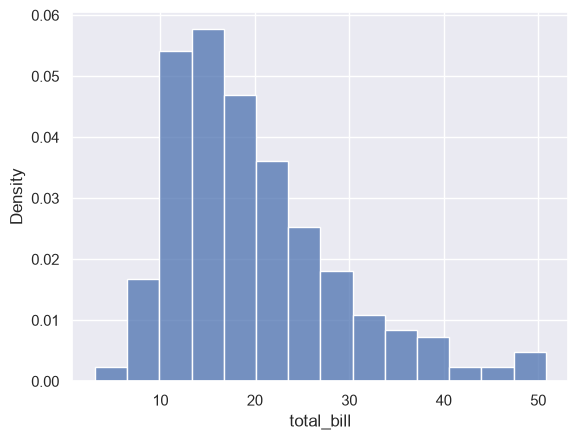

In [28]:
# Histogram showing density instead of counts
sns.histplot(data=tips, x="total_bill", stat="density")

# Display the figure
plt.show()

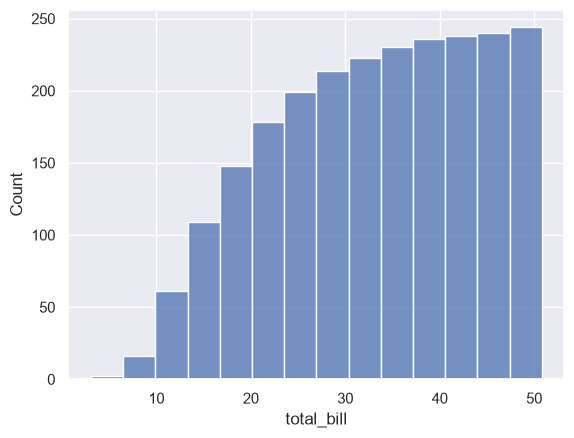

In [29]:
# Cumulative histogram
sns.histplot(data=tips, x="total_bill", cumulative=True)

# Display the figure
plt.show()

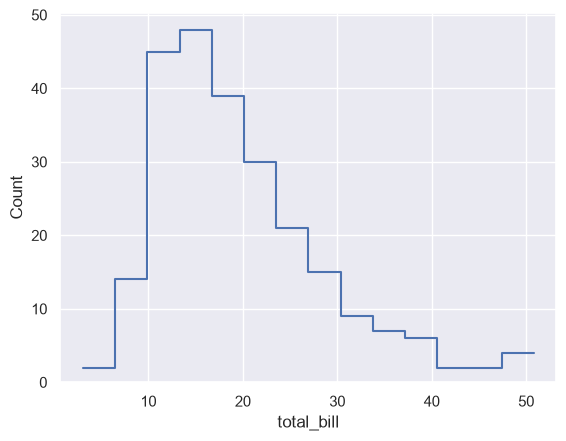

In [30]:
# Step-style histogram with no fill
sns.histplot(data=tips, x="total_bill", element="step", fill=False)

# Display the figure
plt.show()

Overlay groups:

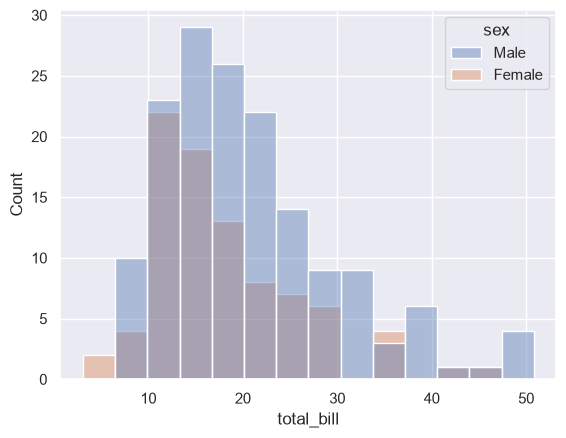

In [31]:
# Overlaid histograms by sex with 40% opacity
sns.histplot(data=tips, x="total_bill", hue="sex", multiple="layer", alpha=0.4)

# Display the figure
plt.show()

Other `multiple` choices include `"stack"`, `"dodge"`, and `"fill"`.

### Kernel density estimate (KDE)

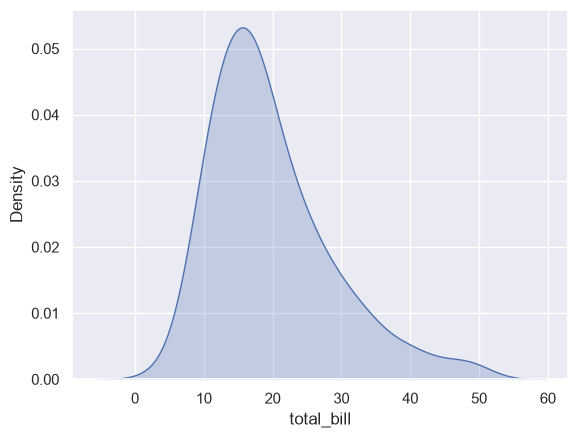

In [32]:
# Filled kernel density estimate of total_bill
sns.kdeplot(data=tips, x="total_bill", fill=True)

# Display the figure
plt.show()

Compare distributions:

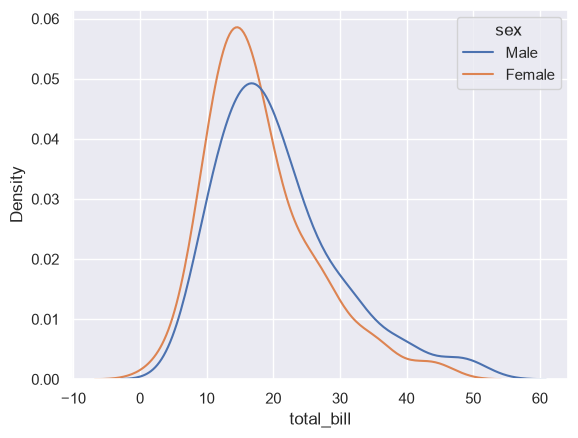

In [33]:
# KDE by sex, each normalized independently
sns.kdeplot(data=tips, x="total_bill", hue="sex", common_norm=False)

# Display the figure
plt.show()

KDE options:

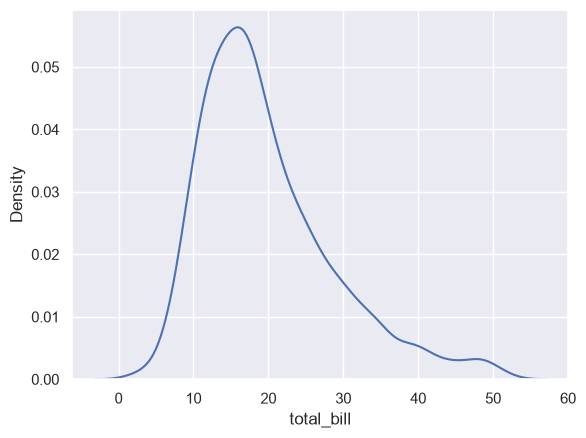

In [34]:
# KDE with a narrower bandwidth (more detail, less smooth)
sns.kdeplot(data=tips, x="total_bill", bw_adjust=0.7)

# Display the figure
plt.show()

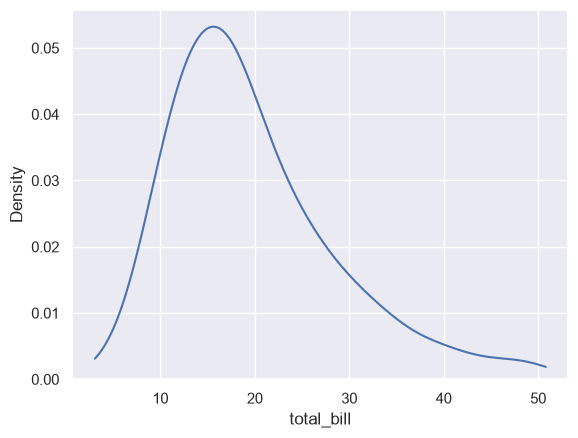

In [35]:
# KDE that stops the curve at the data range (no extrapolation)
sns.kdeplot(data=tips, x="total_bill", cut=0)

# Display the figure
plt.show()

KDE is a smoothed estimate, not the raw observations. Its shape depends
on the bandwidth and can be misleading for small samples or bounded
variables.

### ECDF plot

An empirical cumulative distribution function shows the fraction of
observations less than or equal to each value.

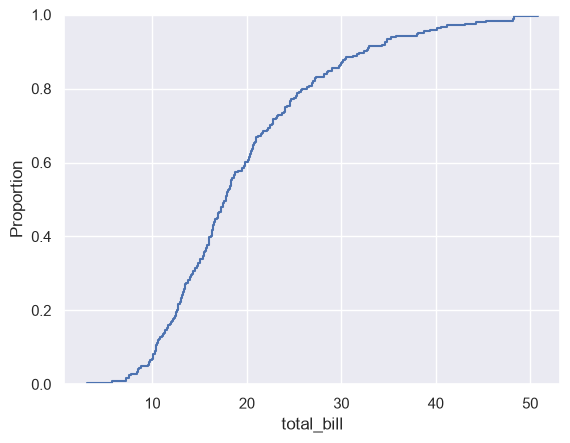

In [36]:
# ECDF of total_bill
sns.ecdfplot(data=tips, x="total_bill")

# Display the figure
plt.show()

Compare groups:

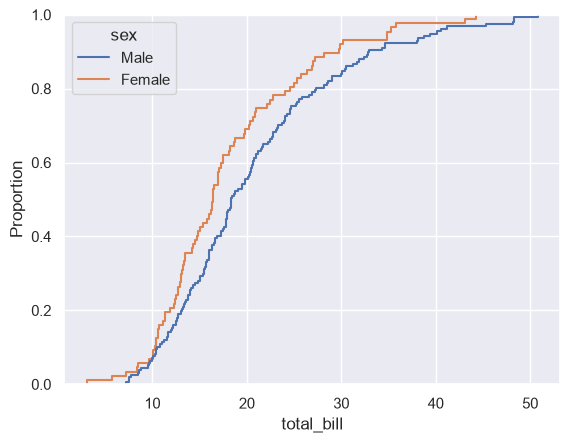

In [37]:
# ECDF by sex
sns.ecdfplot(data=tips, x="total_bill", hue="sex")

# Display the figure
plt.show()

### Rug plot

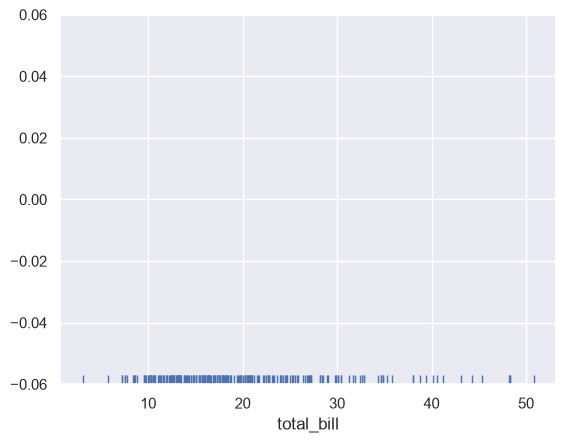

In [38]:
# Rug plot: tick marks for each observation along the x-axis
sns.rugplot(data=tips, x="total_bill")

# Display the figure
plt.show()

Rug marks show individual observations along an axis. They can become
crowded with large datasets.

### Figure-level distribution plots

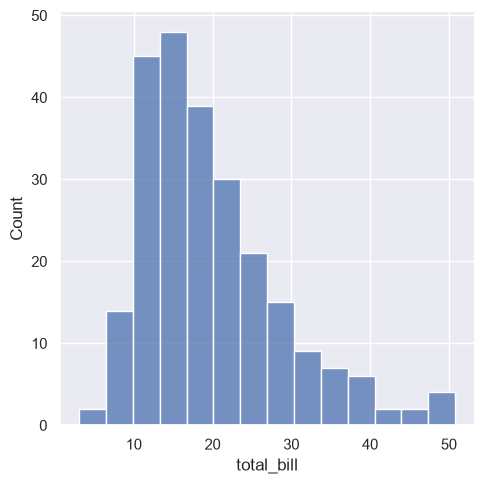

In [39]:
# Figure-level histogram
sns.displot(data=tips, x="total_bill", kind="hist")

# Display the figure
plt.show()

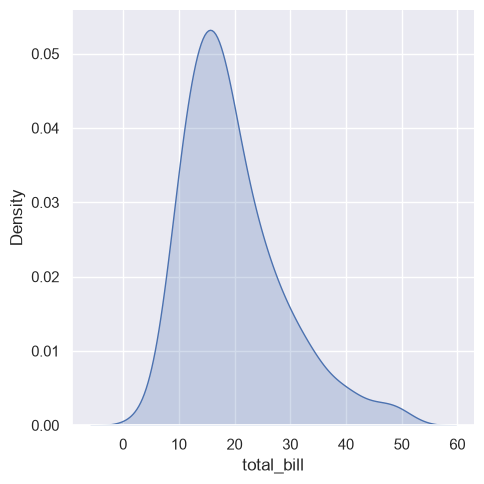

In [40]:
# Figure-level KDE, filled
sns.displot(data=tips, x="total_bill", kind="kde", fill=True)

# Display the figure
plt.show()

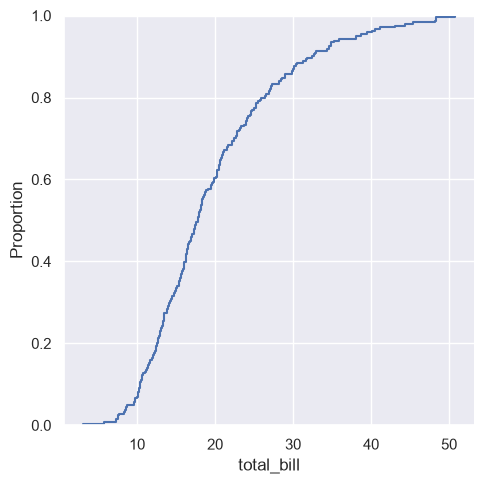

In [41]:
# Figure-level ECDF
sns.displot(data=tips, x="total_bill", kind="ecdf")

# Display the figure
plt.show()

Facet distributions by group:

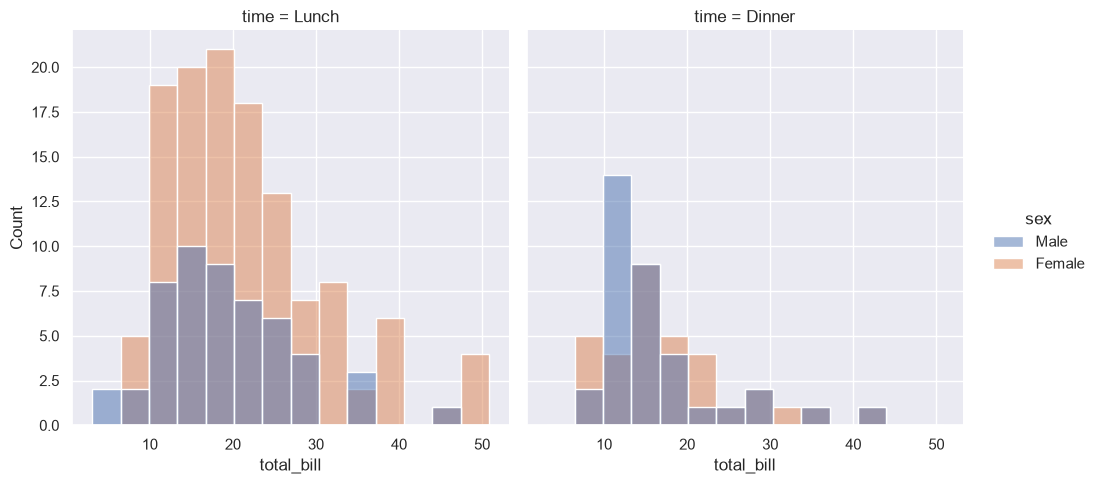

In [42]:
# Faceted histograms: columns by time, colored by sex
sns.displot(data=tips, x="total_bill", col="time", hue="sex", kind="hist")

# Display the figure
plt.show()

## Categorical Plots

Categorical plots compare values across groups. Seaborn supports
categorical variables on either axis.

### Bar plot

A bar plot estimates a statistic for each category (mean by default) and
commonly shows an uncertainty interval.

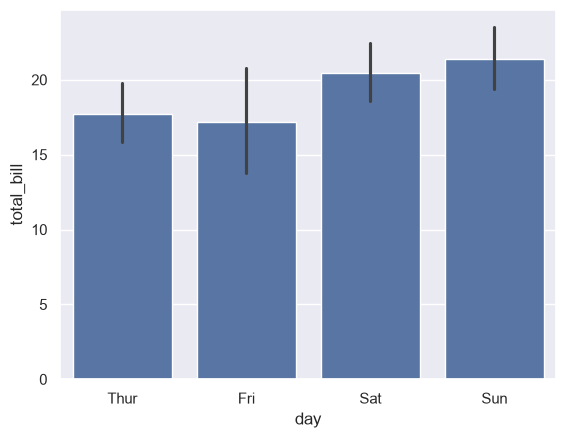

In [43]:
# Bar plot: mean total_bill per day with a 95% confidence interval
sns.barplot(data=tips, x="day", y="total_bill")

# Display the figure
plt.show()

Change the estimator:

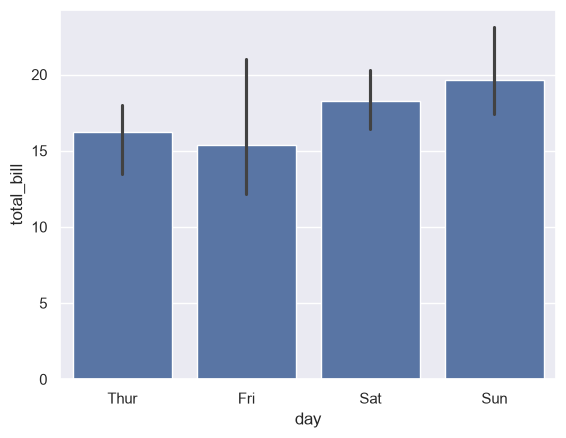

In [44]:
# Bar plot using the median instead of the mean
sns.barplot(data=tips, x="day", y="total_bill", estimator="median")

# Display the figure
plt.show()

For a custom estimator, pass a callable, for example
`estimator=np.median`.

Disable uncertainty intervals when appropriate:

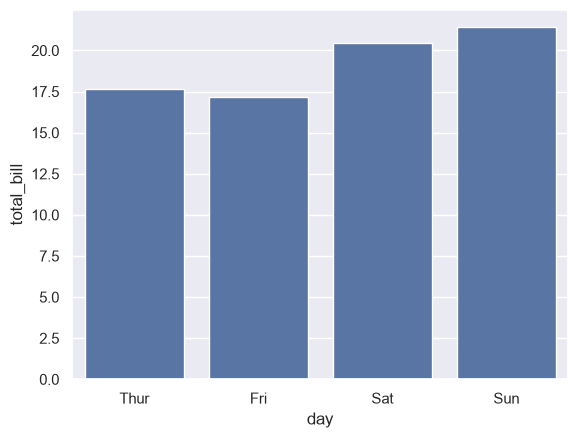

In [45]:
# Bar plot with no uncertainty interval
sns.barplot(data=tips, x="day", y="total_bill", errorbar=None)

# Display the figure
plt.show()

**Important:** `barplot()` summarizes a numeric variable. Use
`countplot()` when the goal is to count rows in each category.

### Count plot

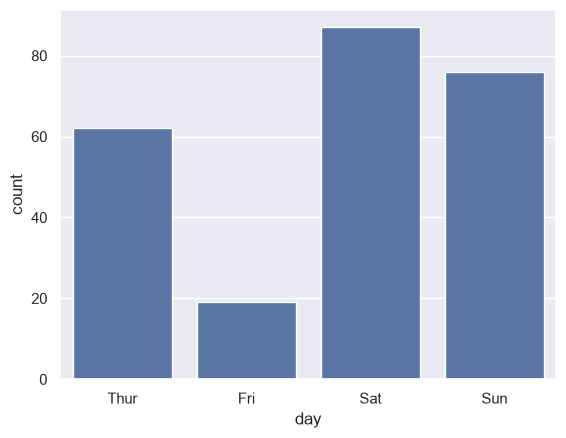

In [46]:
# Count plot: number of rows per day
sns.countplot(data=tips, x="day")

# Display the figure
plt.show()

Count categories by another variable:

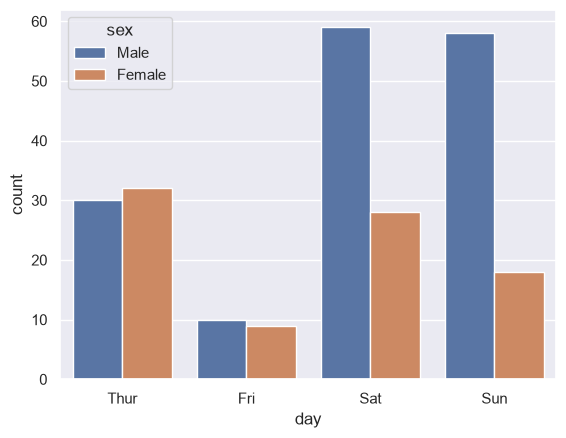

In [47]:
# Count plot of days, colored by sex
sns.countplot(data=tips, x="day", hue="sex")

# Display the figure
plt.show()

### Box plot

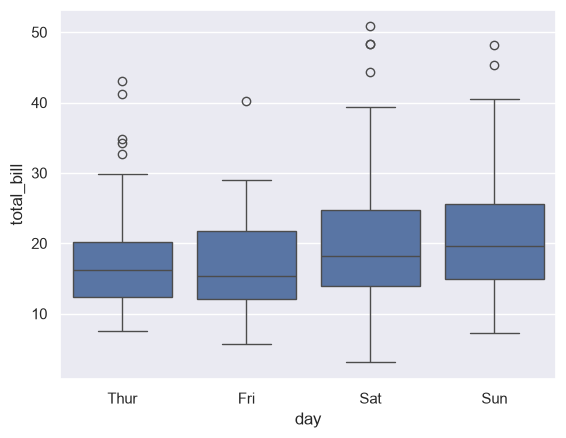

In [48]:
# Box plot of total_bill per day
sns.boxplot(data=tips, x="day", y="total_bill")

# Display the figure
plt.show()

Compare groups:

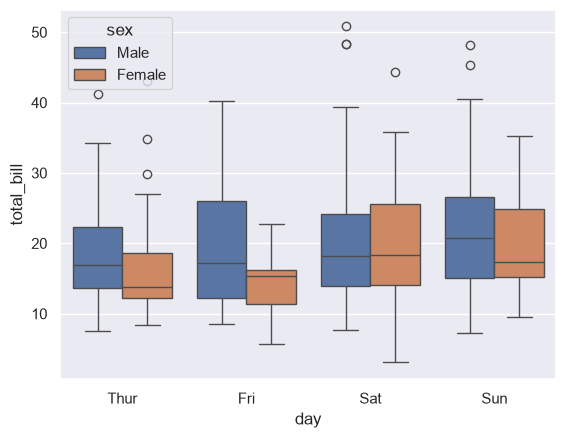

In [49]:
# Box plot of total_bill per day, colored by sex
sns.boxplot(data=tips, x="day", y="total_bill", hue="sex")

# Display the figure
plt.show()

### Violin plot

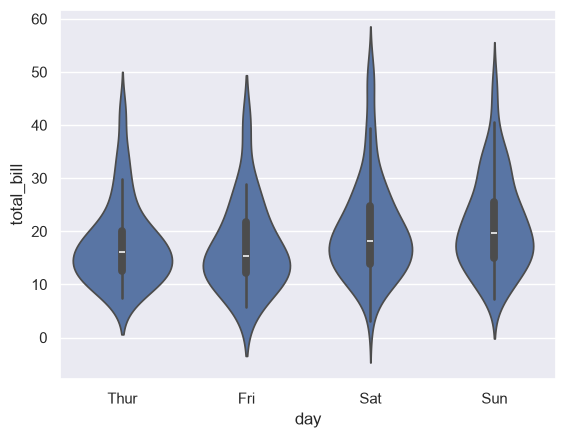

In [50]:
# Violin plot of total_bill per day
sns.violinplot(data=tips, x="day", y="total_bill")

# Display the figure
plt.show()

Useful options include `inner="box"`, `inner="quart"`, `cut=0`, and
`density_norm="width"` (in current Seaborn versions).

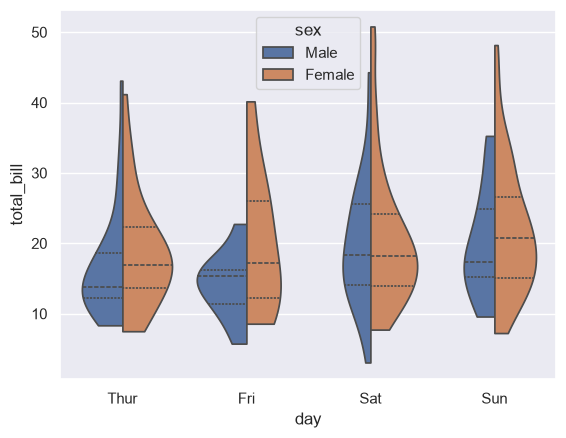

In [51]:
# Split violins comparing sexes, quartile lines inside, no extrapolation
sns.violinplot(data=tips, x="day", y="total_bill",
               hue="sex", split=True, inner="quart", cut=0)

# Display the figure
plt.show()

A split violin is suitable when comparing two hue levels per category.

### Boxen plot

Boxen plots are useful for comparing distributions with larger datasets.

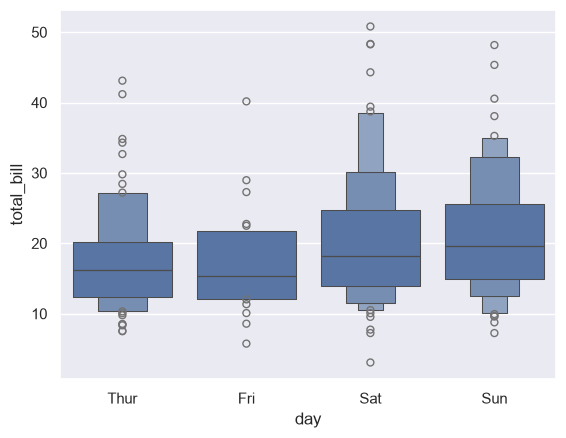

In [52]:
# Boxen plot of total_bill per day
sns.boxenplot(data=tips, x="day", y="total_bill")

# Display the figure
plt.show()

### Strip plot

Shows individual observations, with jitter to reduce overlap.

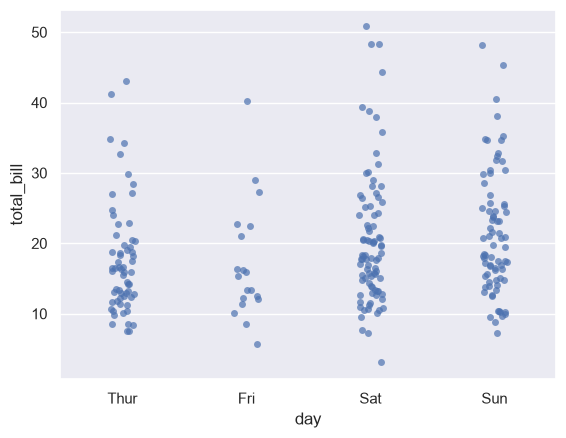

In [53]:
# Strip plot with jitter and 70% opacity
sns.stripplot(data=tips, x="day", y="total_bill", jitter=True, alpha=0.7)

# Display the figure
plt.show()

### Swarm plot

Positions points to reduce overlap.

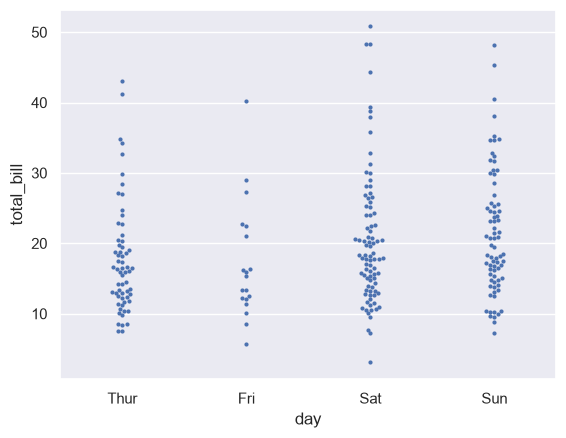

In [54]:
# Swarm plot with small markers
sns.swarmplot(data=tips, x="day", y="total_bill", size=3)

# Display the figure
plt.show()

Swarm plots can become slow or crowded with large datasets.

### Combine distribution and point plots

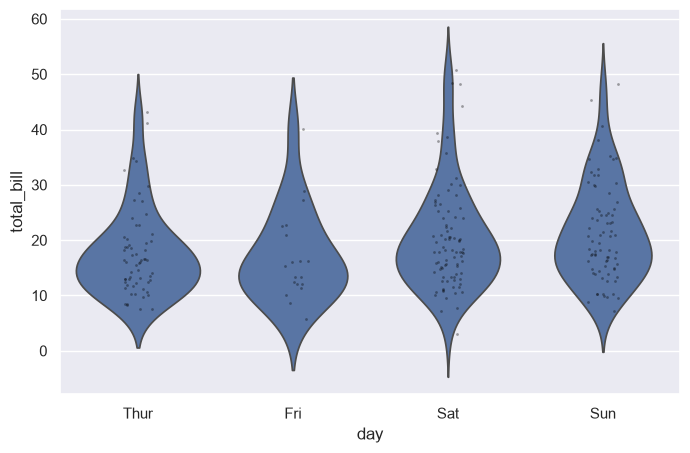

In [55]:
# Create an 8x5 inch figure with one axes
fig, ax = plt.subplots(figsize=(8, 5))

# Violin plot with no inner markings, drawn into the axes
sns.violinplot(data=tips, x="day", y="total_bill", inner=None, ax=ax)

# Overlay small semi-transparent black points
sns.stripplot(data=tips, x="day", y="total_bill", color="black",
              alpha=0.35, size=2, ax=ax)

# Display the figure
plt.show()

### Point plot

Shows a summary estimate and uncertainty interval across categories.

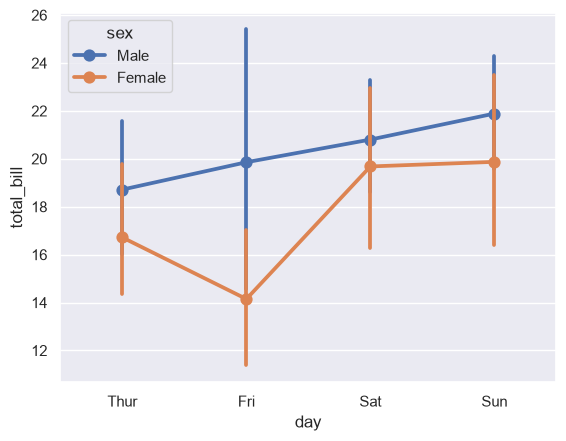

In [56]:
# Point plot of total_bill per day, colored by sex
sns.pointplot(data=tips, x="day", y="total_bill", hue="sex")

# Display the figure
plt.show()

### Figure-level categorical plots

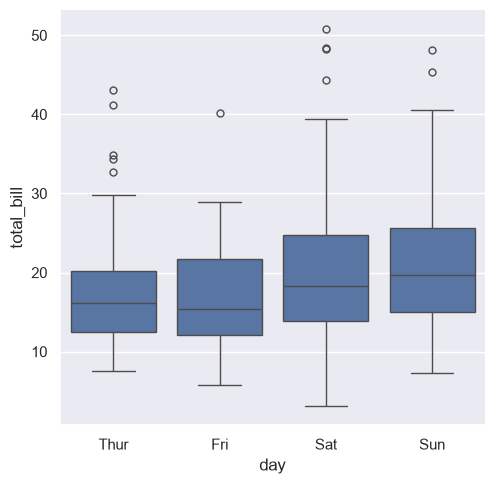

In [57]:
# Figure-level box plot
sns.catplot(data=tips, x="day", y="total_bill", kind="box")

# Display the figure
plt.show()

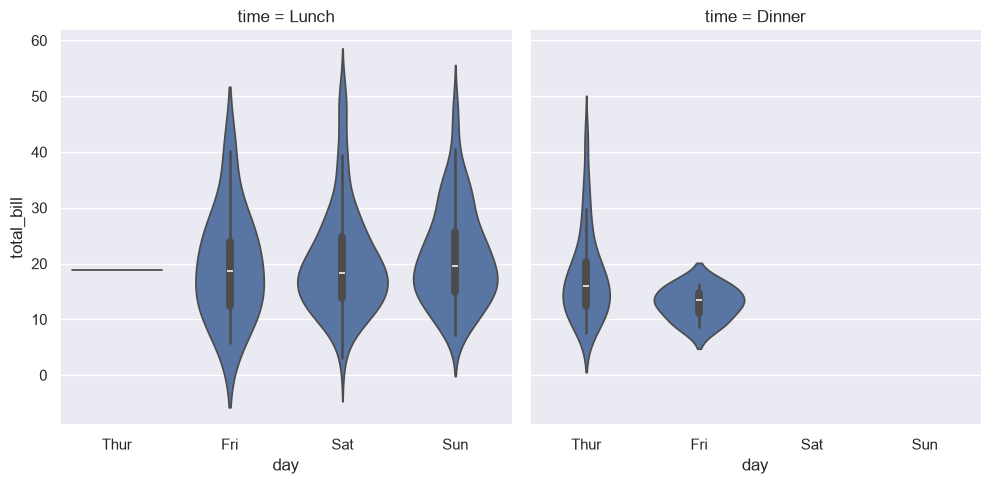

In [58]:
# Figure-level violin plot, faceted into columns by time
sns.catplot(data=tips, x="day", y="total_bill", kind="violin", col="time")

# Display the figure
plt.show()

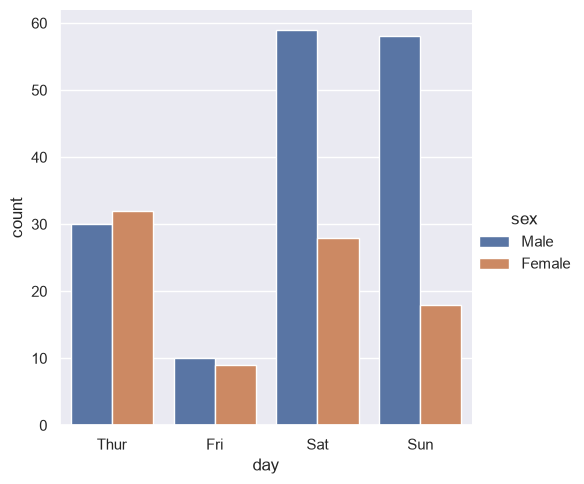

In [59]:
# Figure-level count plot of days, colored by sex
sns.catplot(data=tips, x="day", kind="count", hue="sex")

# Display the figure
plt.show()

Available categorical kinds commonly include `"strip"`, `"swarm"`,
`"box"`, `"violin"`, `"boxen"`, `"point"`, `"bar"`, and `"count"`.

## Regression Plots

Seaborn provides convenient visualizations of relationships and fitted
regression models.

### Regression plot

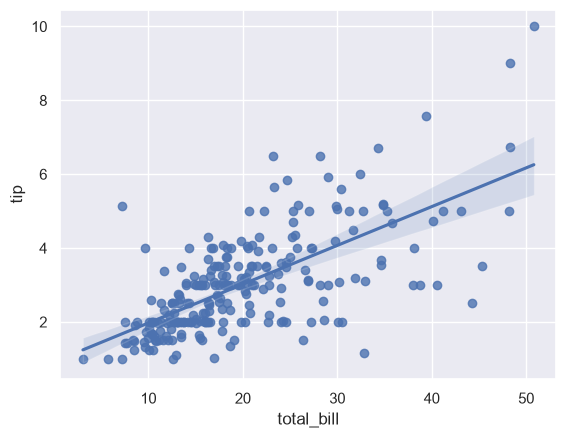

In [60]:
# Scatter plot with a fitted regression line and confidence interval
sns.regplot(data=tips, x="total_bill", y="tip")

# Display the figure
plt.show()

Show scatter points and a fitted regression line with a confidence
interval.

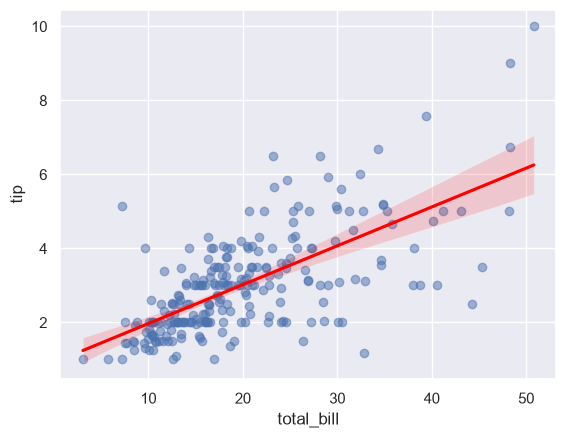

In [61]:
# Regression plot: semi-transparent points, red fitted line
sns.regplot(data=tips, x="total_bill", y="tip",
            scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})

# Display the figure
plt.show()

### Disable the confidence interval

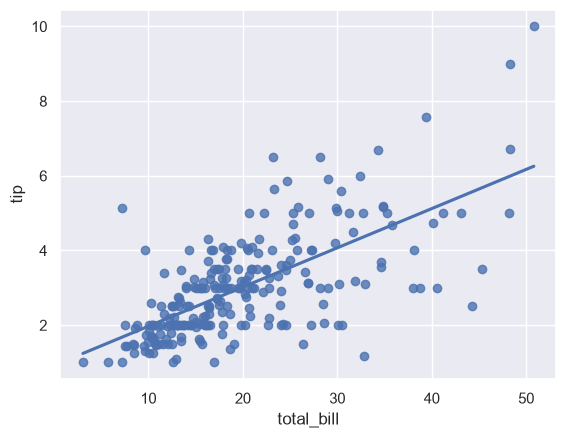

In [62]:
# Regression plot with no confidence interval
# (regplot uses ci=...; other seaborn functions use errorbar=... in current versions)
sns.regplot(data=tips, x="total_bill", y="tip", ci=None)

# Display the figure
plt.show()

### Polynomial regression

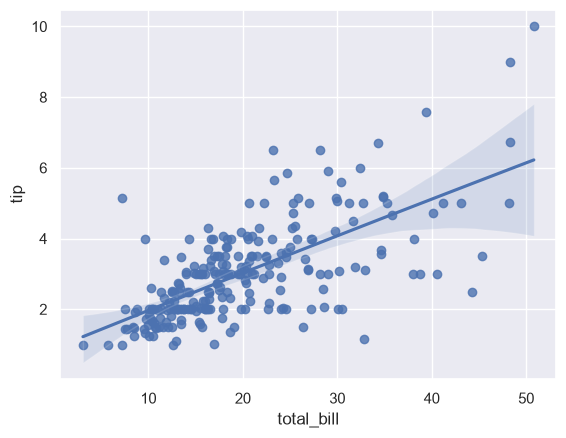

In [63]:
# Quadratic (order=2) regression fit
sns.regplot(data=tips, x="total_bill", y="tip", order=2)

# Display the figure
plt.show()

A higher-order polynomial can overfit. Use it only when justified by the
data and analysis.

### Logistic regression visualization

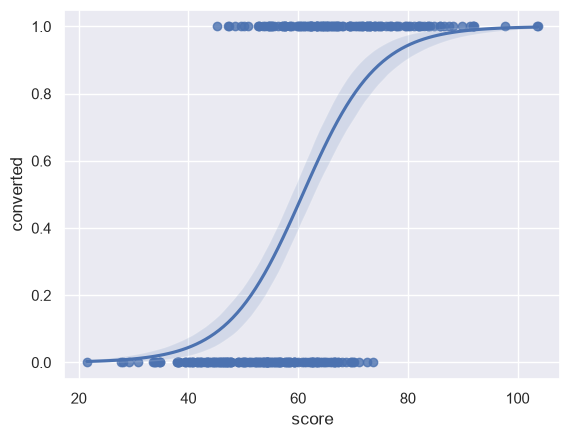

In [64]:
# Synthetic data: a test score and a binary outcome (converted or not)
rng = np.random.default_rng(42)
scores = rng.normal(60, 15, 300)
converted = (scores + rng.normal(0, 10, 300) > 60).astype(int)
df = pd.DataFrame({"score": scores, "converted": converted})

# Logistic regression curve of the binary outcome on the score
sns.regplot(data=df, x="score", y="converted", logistic=True)

# Display the figure
plt.show()

The data must contain a suitable binary outcome and a predictor.
Logistic regression visualization is not a substitute for full model
diagnostics.

### Residual plot

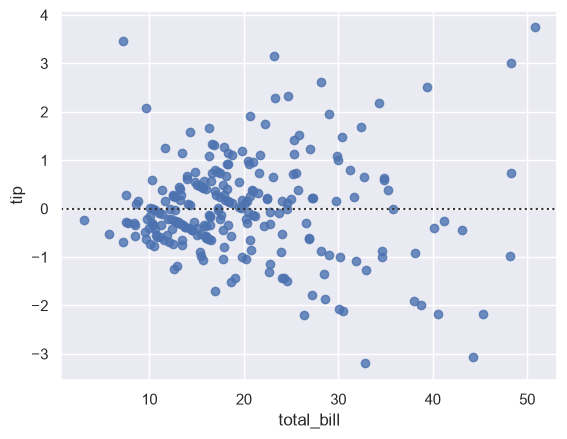

In [65]:
# Residuals of the tip ~ total_bill regression fit
sns.residplot(data=tips, x="total_bill", y="tip")

# Display the figure
plt.show()

Residual plots can help identify patterns or changing variance. Check
the model assumptions and context before drawing conclusions.

### Figure-level regression plot

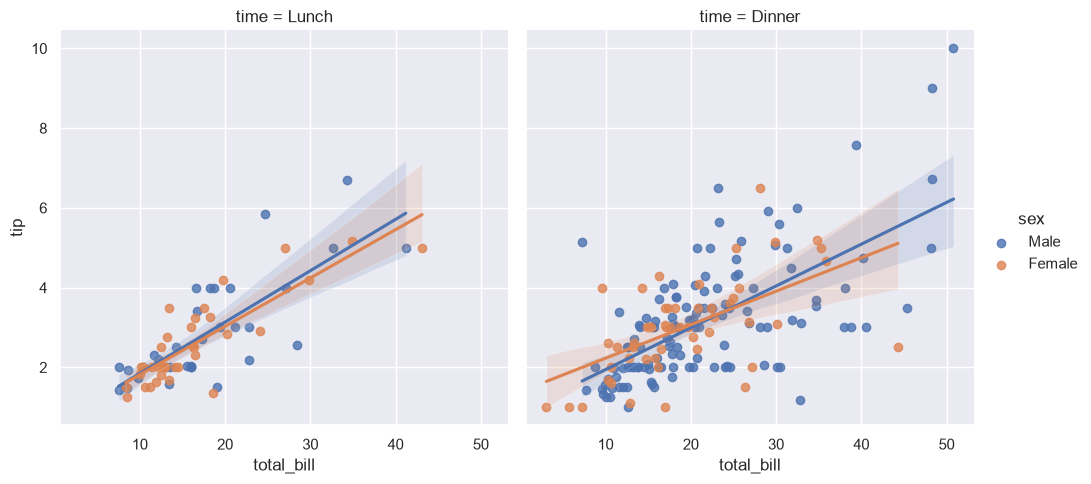

In [66]:
# Figure-level regression plot, faceted by time and colored by sex
sns.lmplot(data=tips, x="total_bill", y="tip", hue="sex", col="time")

# Display the figure
plt.show()

`regplot()` works on one axes. `lmplot()` is figure-level and supports
facets such as `col` and `row`.

## Pairwise and Joint Relationships

### Pair plot

Creates pairwise relationships for several variables.

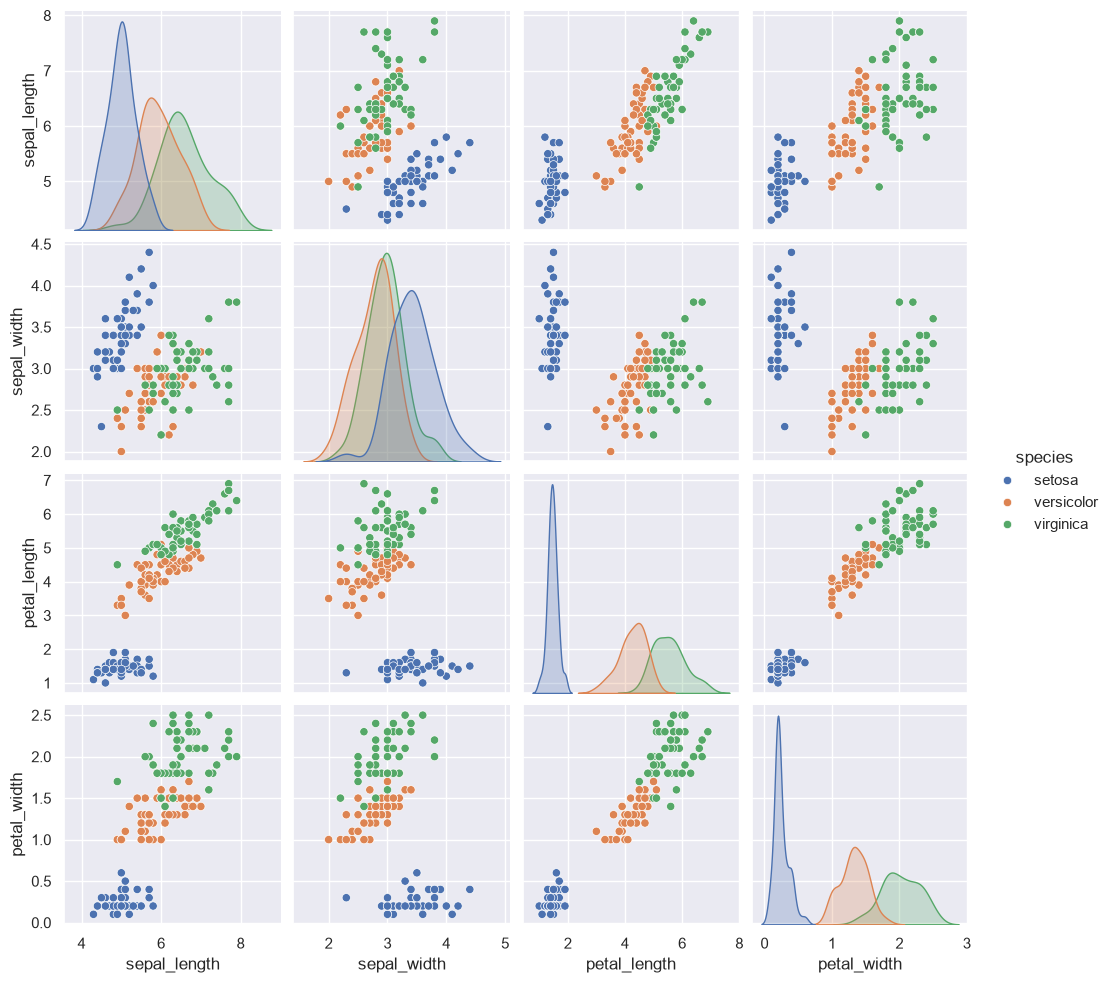

In [67]:
# Load the built-in iris dataset
iris = sns.load_dataset("iris")

# Pairwise scatter plots and histograms, colored by species
sns.pairplot(iris, hue="species")

# Display the figure
plt.show()

Select variables:

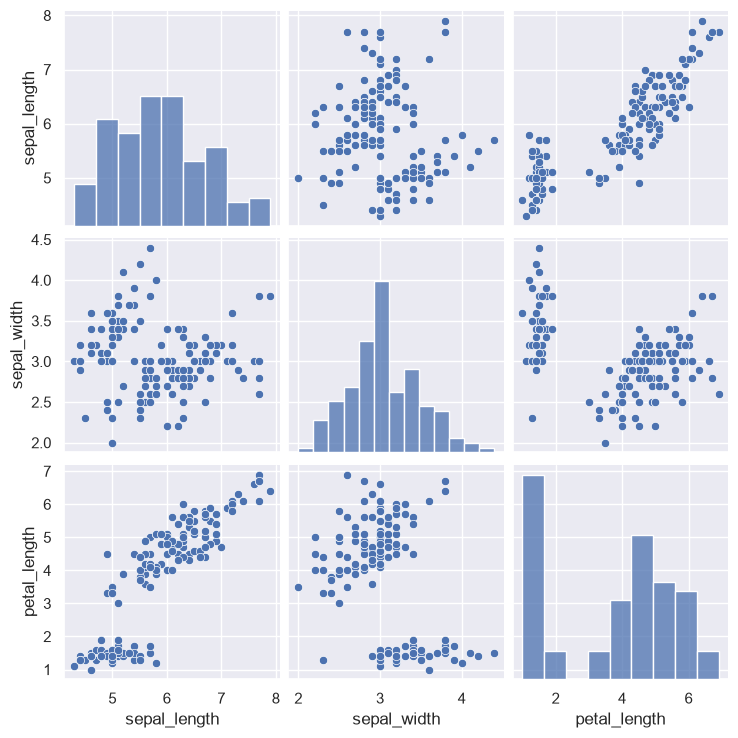

In [68]:
# Pair plot of only three selected features
sns.pairplot(iris, vars=["sepal_length", "sepal_width", "petal_length"])

# Display the figure
plt.show()

Change the diagonal plots:

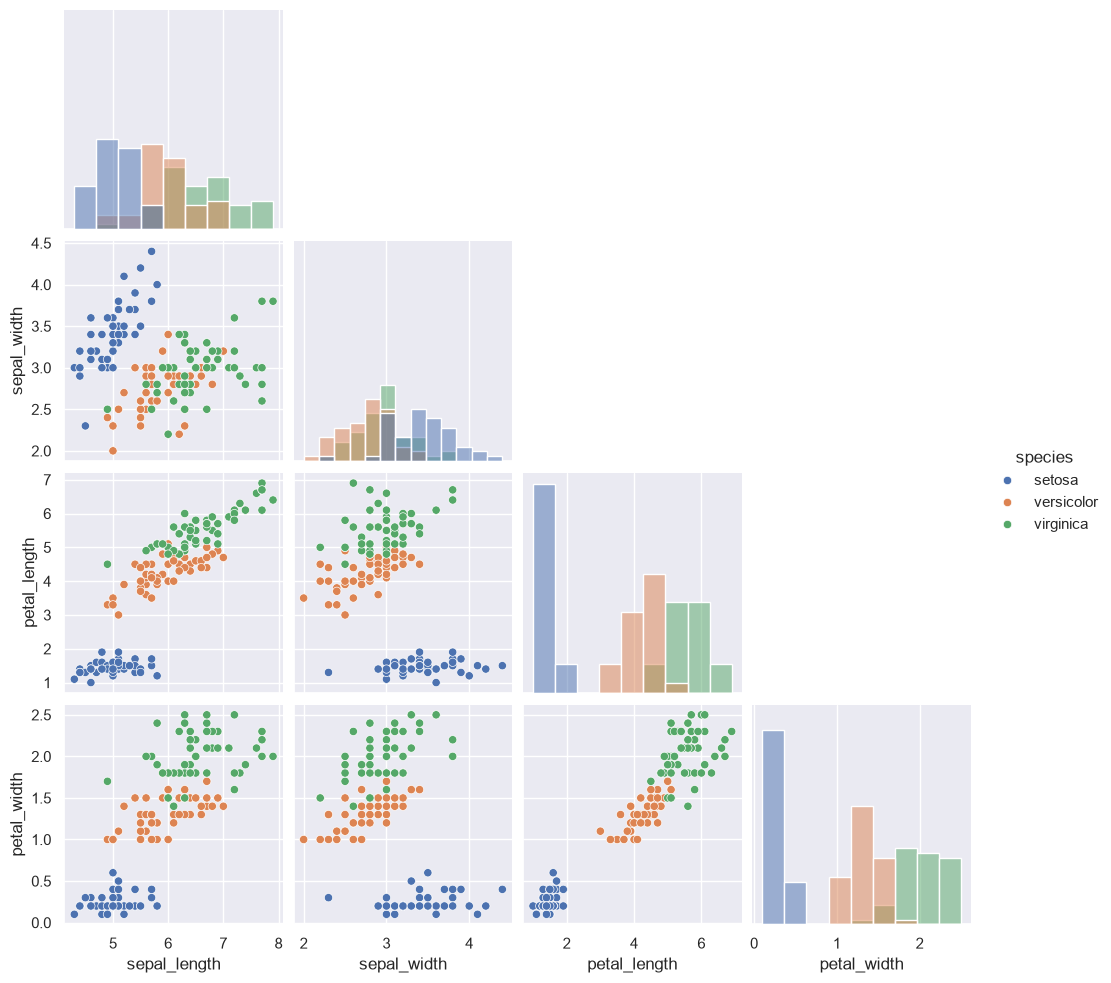

In [69]:
# Pair plot with histograms on the diagonal, lower triangle only
sns.pairplot(iris, hue="species", diag_kind="hist", corner=True)

# Display the figure
plt.show()

Pair plots can become expensive and crowded when there are many columns.
Select a meaningful subset.

### PairGrid for custom layouts

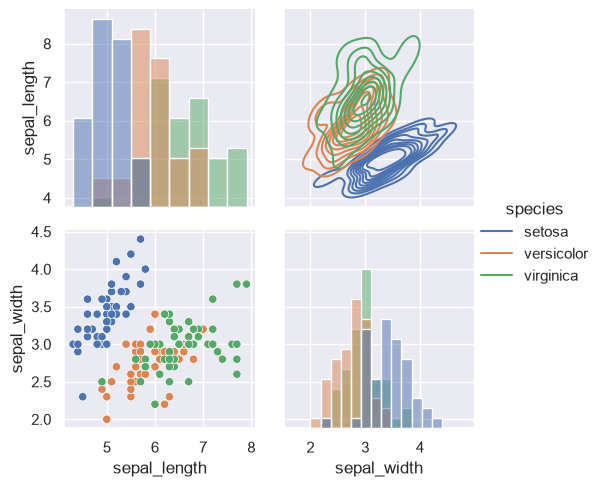

In [70]:
# Create a custom 2x2 pair grid for two variables, colored by species
g = sns.PairGrid(iris, vars=["sepal_length", "sepal_width"], hue="species")

# Lower triangle: scatter plots
g.map_lower(sns.scatterplot)

# Diagonal: histograms
g.map_diag(sns.histplot)

# Upper triangle: KDE plots
g.map_upper(sns.kdeplot)

# Add the legend
g.add_legend()

# Display the figure
plt.show()

### Joint plot

Combines a bivariate plot with marginal distributions.

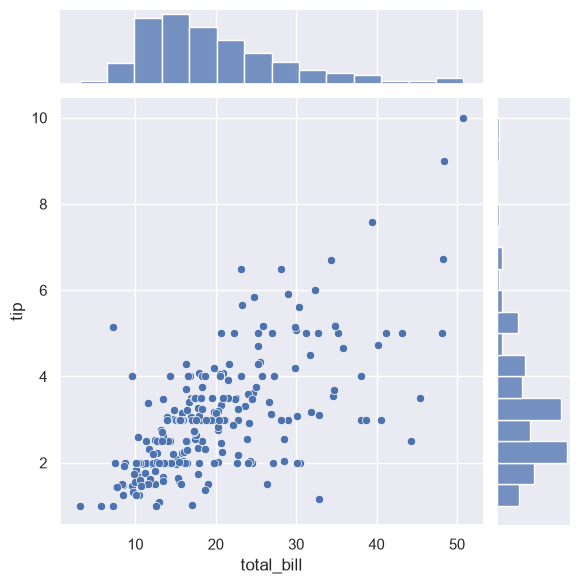

In [71]:
# Joint plot: scatter in the center, histograms on the margins
sns.jointplot(data=tips, x="total_bill", y="tip")

# Display the figure
plt.show()

Choose the joint plot kind:

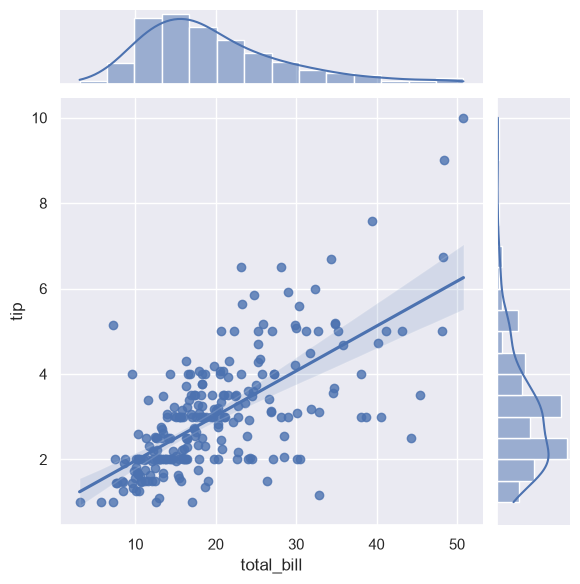

In [72]:
# Joint plot with a regression fit
sns.jointplot(data=tips, x="total_bill", y="tip", kind="reg")

# Display the figure
plt.show()

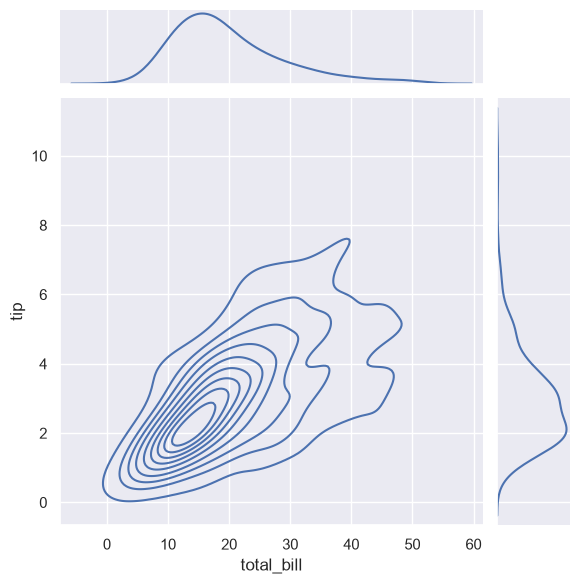

In [73]:
# Joint plot with KDE contours
sns.jointplot(data=tips, x="total_bill", y="tip", kind="kde")

# Display the figure
plt.show()

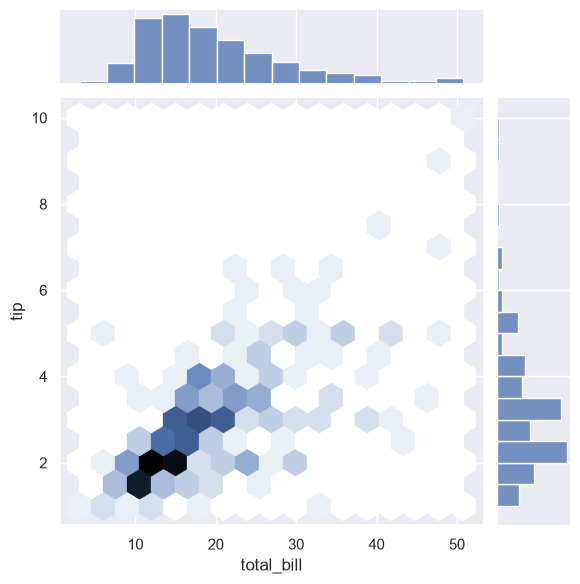

In [74]:
# Joint plot with hexagonal binning
sns.jointplot(data=tips, x="total_bill", y="tip", kind="hex")

# Display the figure
plt.show()

Common kinds are `"scatter"`, `"kde"`, `"hist"`, `"hex"`, and `"reg"`.

### JointGrid for custom joint plots

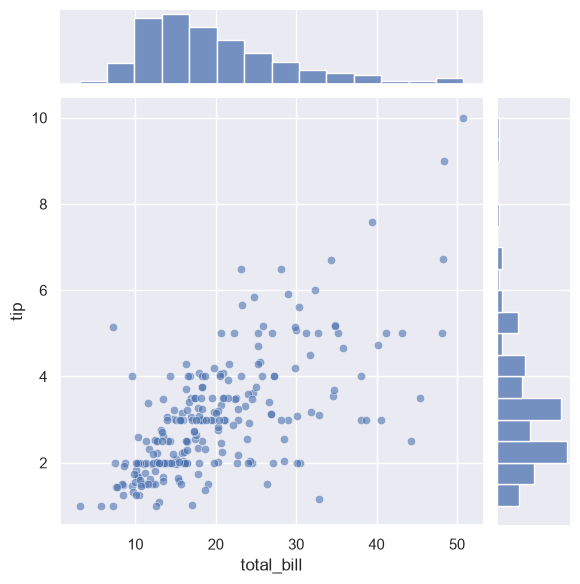

In [75]:
# Create an empty joint grid
g = sns.JointGrid(data=tips, x="total_bill", y="tip")

# Custom center plot: semi-transparent scatter
g.plot_joint(sns.scatterplot, alpha=0.6)

# Custom margin plots: histograms
g.plot_marginals(sns.histplot)

# Display the figure
plt.show()

## Heatmaps and Correlation Analysis

### Correlation matrix

In [76]:
# Keep only the numeric columns of the tips dataset
numeric = tips.select_dtypes(include="number")

# Compute the Pearson correlation matrix
corr = numeric.corr()

# Print the correlation matrix
print(corr)

            total_bill       tip      size
total_bill    1.000000  0.675734  0.598315
tip           0.675734  1.000000  0.489299
size          0.598315  0.489299  1.000000


### Correlation heatmap

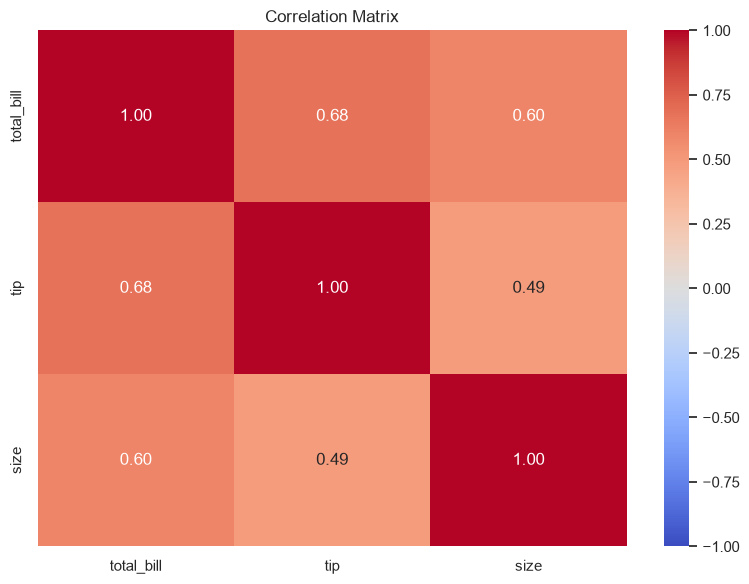

In [77]:
# Create an 8x6 inch figure
plt.figure(figsize=(8, 6))

# Draw the heatmap with values annotated to 2 decimals, centered at 0
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0)

# Add a title
plt.title("Correlation Matrix")

# Tighten the layout
plt.tight_layout()

# Display the figure
plt.show()

Useful parameters:
- `annot=True`: write values in cells.
- `fmt=".2f"`: format values to two decimal places.
- `cmap`: select a colormap.
- `vmin`, `vmax`: set the color range.
- `center=0`: center a diverging palette around zero.
- `linewidths`: space between cells.
- `mask`: hide selected cells.

### Mask the upper triangle

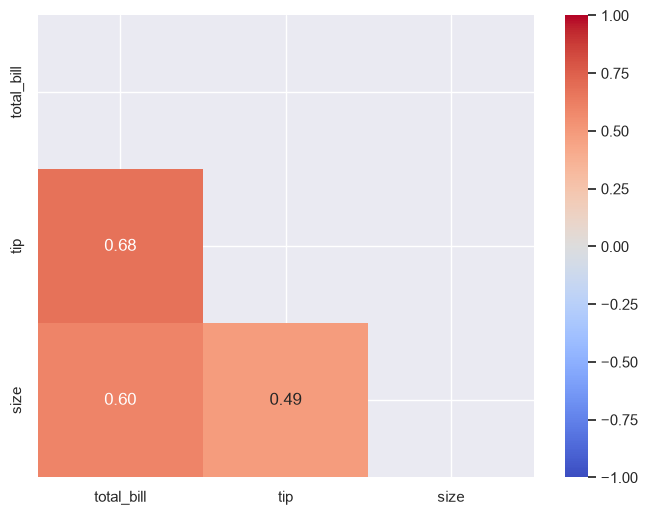

In [78]:
# Boolean mask that is True for the upper triangle (including diagonal)
mask = np.triu(np.ones_like(corr, dtype=bool))

# Create an 8x6 inch figure
plt.figure(figsize=(8, 6))

# Draw the heatmap hiding the masked (upper triangle) cells
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0)

# Display the figure
plt.show()

### Pivot-table heatmap

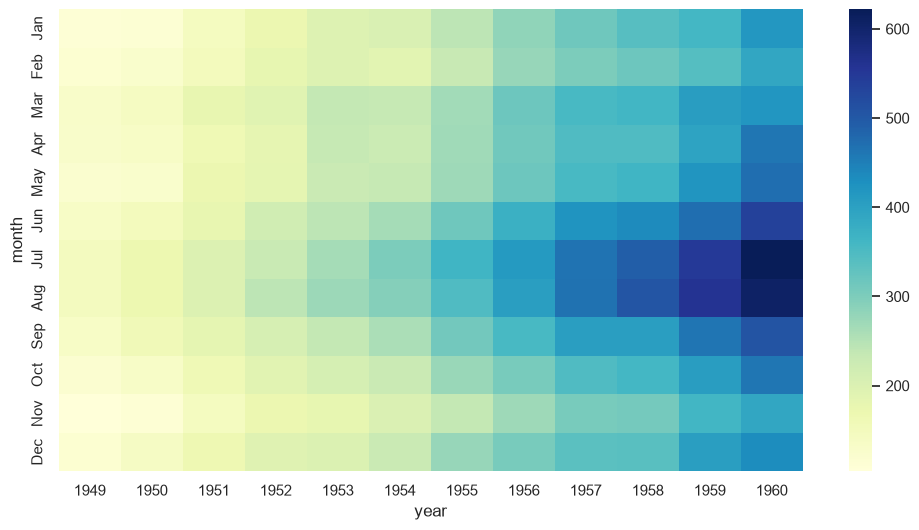

In [79]:
# Pivot flights data: months as rows, years as columns
pivot = flights.pivot(index="month", columns="year", values="passengers")

# Create a wide 12x6 inch figure
plt.figure(figsize=(12, 6))

# Draw the heatmap with the YlGnBu colormap
sns.heatmap(pivot, cmap="YlGnBu")

# Display the figure
plt.show()

Correlation describes association, not causation. Pearson correlation
may miss nonlinear relationships and can be affected by outliers.

### Clustered heatmap (bonus)

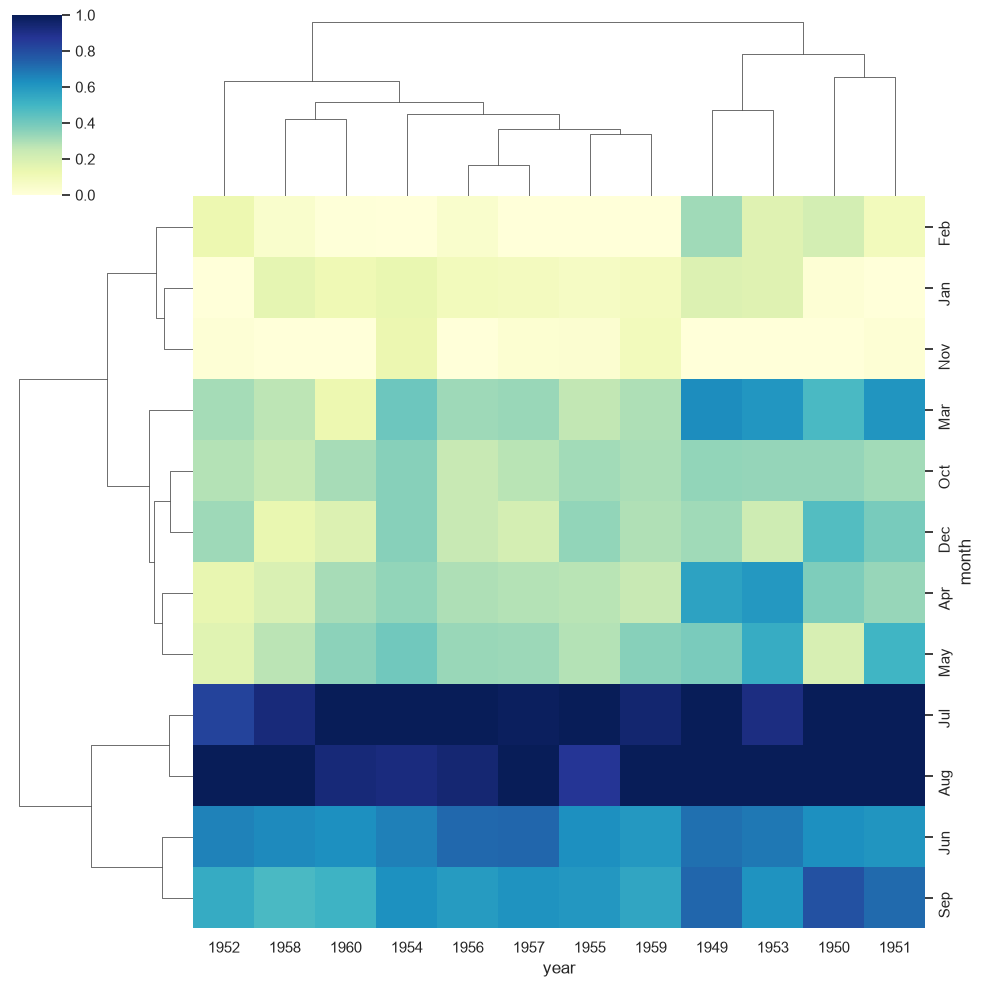

In [80]:
# Clustered heatmap of the flights pivot: rows/columns reordered by similarity
sns.clustermap(pivot, cmap="YlGnBu", standard_scale=1)

# Display the figure
plt.show()

## Faceting and Small Multiples

Faceting creates comparable plots across subsets of data.

### `relplot()` facets

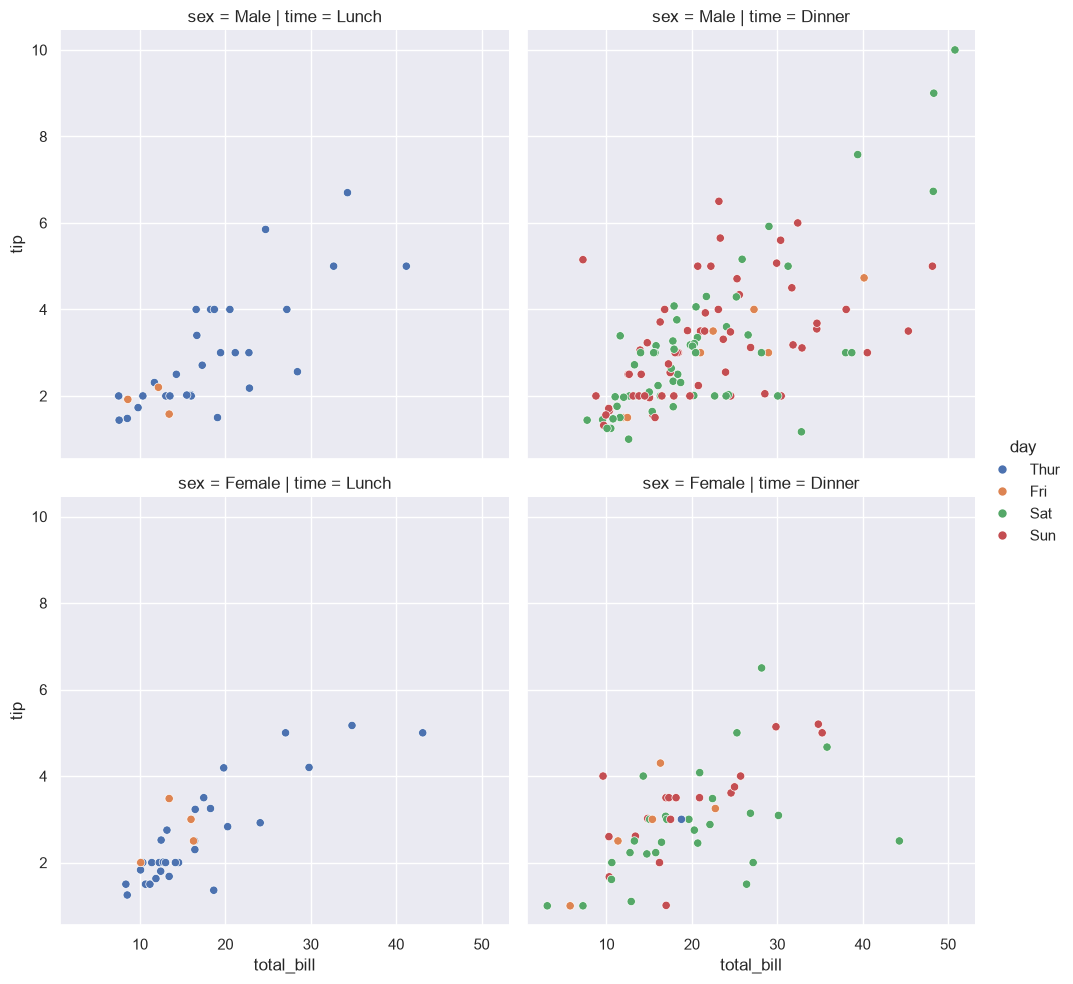

In [81]:
# Relational plot faceted by time (columns) and sex (rows), colored by day
sns.relplot(data=tips, x="total_bill", y="tip",
            col="time", row="sex", hue="day")

# Display the figure
plt.show()

### `displot()` facets

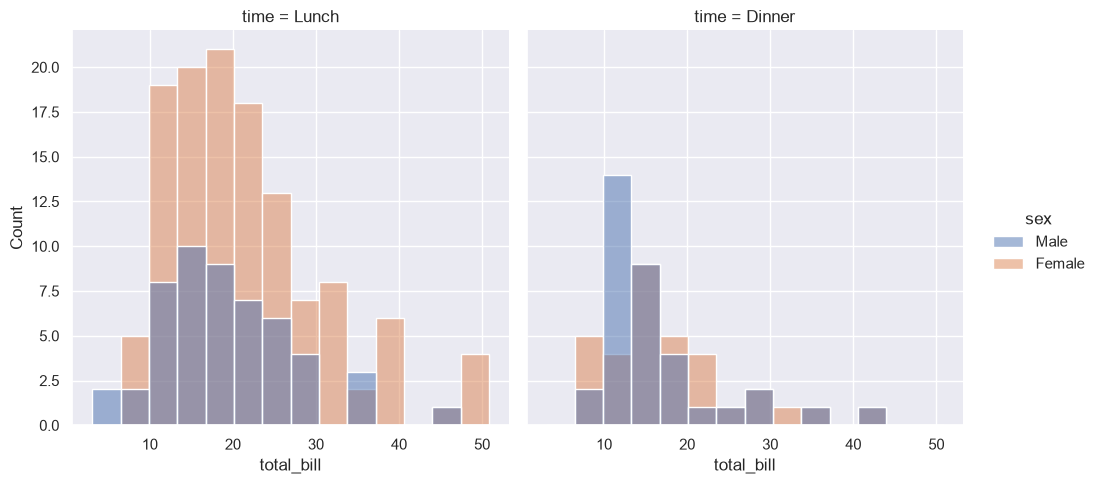

In [82]:
# Distribution plot faceted by time, colored by sex
sns.displot(data=tips, x="total_bill", col="time", hue="sex", kind="hist")

# Display the figure
plt.show()

### `catplot()` facets

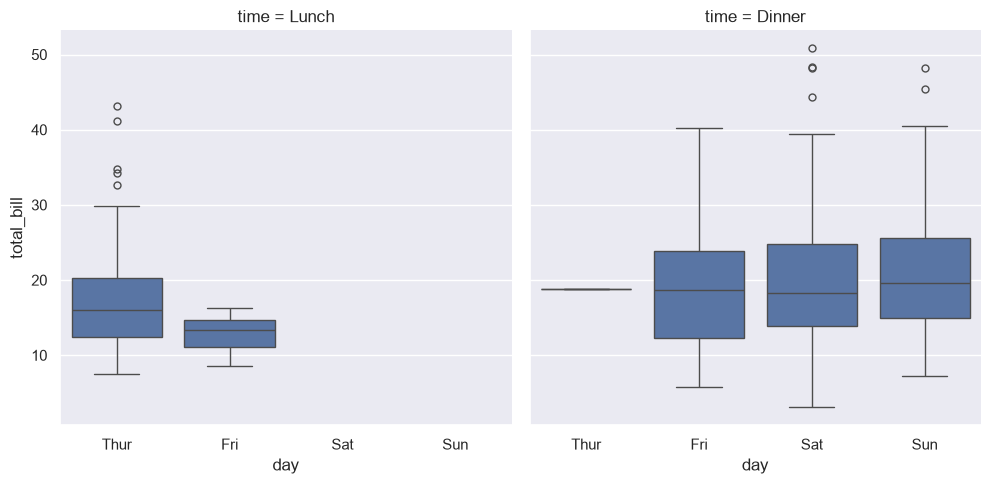

In [83]:
# Categorical box plot faceted by time
sns.catplot(data=tips, x="day", y="total_bill",
            col="time", kind="box")

# Display the figure
plt.show()

### Customize a FacetGrid

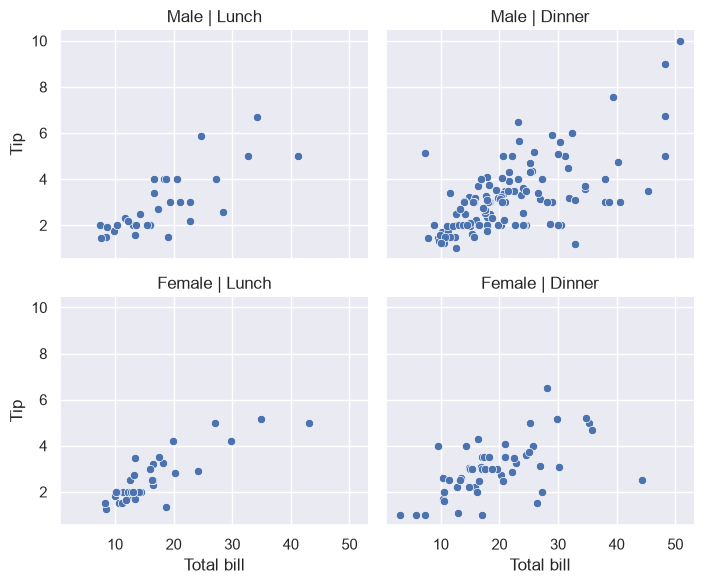

In [84]:
# Create a FacetGrid: columns by time, rows by sex
g = sns.FacetGrid(tips, col="time", row="sex", height=3, aspect=1.2)

# Map a scatter plot onto each facet
g.map_dataframe(sns.scatterplot, x="total_bill", y="tip")

# Set the axis labels on all facets
g.set_axis_labels("Total bill", "Tip")

# Set the facet titles from the row and column values
g.set_titles(row_template="{row_name}", col_template="{col_name}")

# Display the figure
plt.show()

### Set shared axes and ordering

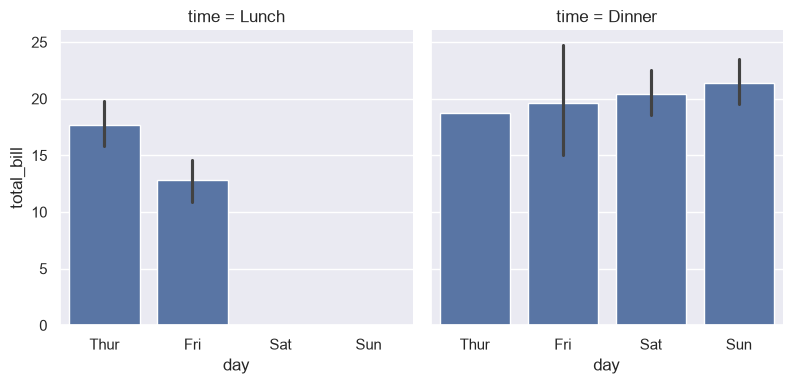

In [85]:
# Faceted bar plot with explicit day order and shared y-axis
sns.catplot(
    data=tips, x="day", y="total_bill",
    col="time", kind="bar",
    order=["Thur", "Fri", "Sat", "Sun"],
    sharey=True, height=4, aspect=1
)

# Display the figure
plt.show()

Facets are useful for comparisons when the same axes and scales are
retained across panels.

## Data Preparation for Seaborn

Seaborn does not replace data cleaning. Inspect data before plotting.

In [86]:
# Rebuild the small example DataFrame
df = pd.DataFrame({
    "day": ["Mon", "Tue", "Wed", "Mon", "Tue", "Wed"],
    "group": ["A", "A", "A", "B", "B", "B"],
    "sales": [20, 25, 22, 30, 28, 35],
    "customers": [10, 12, 11, 15, 14, 18]
})

# Preview the first rows
print(df.head())

# Data types and missing values
print(df.info())

# Missing values per column
print(df.isna().sum())

# Number of duplicate rows
print(df.duplicated().sum())

# Summary statistics for all columns
print(df.describe(include="all"))

   day group  sales  customers
0  Mon     A     20         10
1  Tue     A     25         12
2  Wed     A     22         11
3  Mon     B     30         15
4  Tue     B     28         14
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   day        6 non-null      str  
 1   group      6 non-null      str  
 2   sales      6 non-null      int64
 3   customers  6 non-null      int64
dtypes: int64(2), str(2)
memory usage: 324.0 bytes
None
day          0
group        0
sales        0
customers    0
dtype: int64
0
        day group      sales  customers
count     6     6   6.000000   6.000000
unique    3     2        NaN        NaN
top     Mon     A        NaN        NaN
freq      2     3        NaN        NaN
mean    NaN   NaN  26.666667  13.333333
std     NaN   NaN   5.501515   2.943920
min     NaN   NaN  20.000000  10.000000
25%     NaN   NaN  22.750000  11.250000
50%   

### Handle missing values deliberately

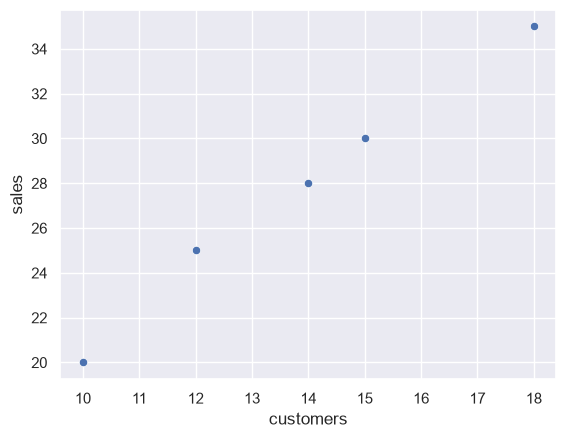

In [87]:
# Rebuild the example DataFrame with a missing value
df = pd.DataFrame({
    "day": ["Mon", "Tue", "Wed", "Mon", "Tue", "Wed"],
    "group": ["A", "A", "A", "B", "B", "B"],
    "sales": [20, 25, None, 30, 28, 35],
    "customers": [10, 12, 11, 15, 14, 18]
})

# Keep only rows with complete sales and customers
plot_df = df.dropna(subset=["sales", "customers"])

# Scatter plot of the complete rows
sns.scatterplot(data=plot_df, x="customers", y="sales")

# Display the figure
plt.show()

Do not impute or remove values without considering why they are missing.

### Set category order

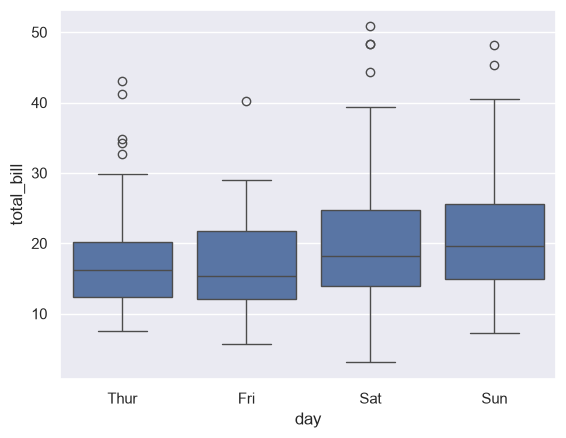

In [88]:
# Explicit chronological order for the days
day_order = ["Thur", "Fri", "Sat", "Sun"]

# Box plot with the custom day order
sns.boxplot(data=tips, x="day", y="total_bill", order=day_order)

# Display the figure
plt.show()

### Convert a column to categorical

In [89]:
# Rebuild the small example DataFrame
df = pd.DataFrame({
    "day": ["Mon", "Tue", "Wed", "Mon", "Tue", "Wed"],
    "group": ["A", "A", "A", "B", "B", "B"],
    "sales": [20, 25, 22, 30, 28, 35],
    "customers": [10, 12, 11, 15, 14, 18]
})

# Convert "group" to an ordered categorical column
df["group"] = pd.Categorical(df["group"], categories=["A", "B", "C"], ordered=True)

# Show the new data type
print(df["group"].dtype)

category


### Long and wide data

Long form:

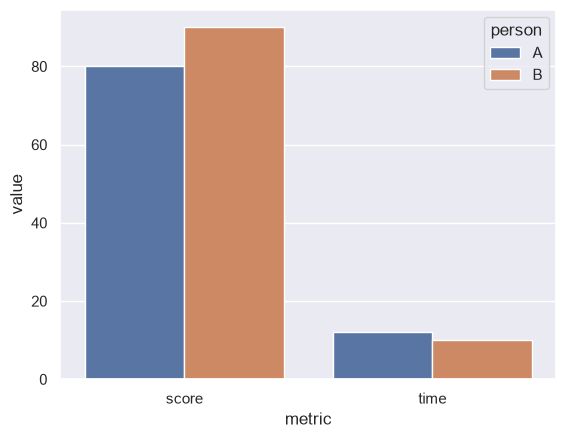

In [90]:
# Long-form DataFrame: one row per person-metric observation
long_df = pd.DataFrame({
    "person": ["A", "A", "B", "B"],
    "metric": ["score", "time", "score", "time"],
    "value": [80, 12, 90, 10]
})

# Bar plot of values by metric, colored by person
sns.barplot(data=long_df, x="metric", y="value", hue="person")

# Display the figure
plt.show()

Wide form is useful for some functions, but long form is often easier to
use with `x`, `y`, and `hue`.

## Time-Series Visualization

In [91]:
# 90 daily dates starting 2025-01-01
dates = pd.date_range("2025-01-01", periods=90, freq="D")

# Reproducible random generator
rng = np.random.default_rng(42)

# DataFrame of daily values around 100
ts = pd.DataFrame({"date": dates, "value": 100 + rng.normal(0, 8, 90)})

# 7-day moving average column
ts["moving_avg"] = ts["value"].rolling(7).mean()

# Show the first rows
print(ts.head())

        date       value  moving_avg
0 2025-01-01  102.437737         NaN
1 2025-01-02   91.680127         NaN
2 2025-01-03  106.003610         NaN
3 2025-01-04  107.524518         NaN
4 2025-01-05   84.391718         NaN


### Line plot with moving average

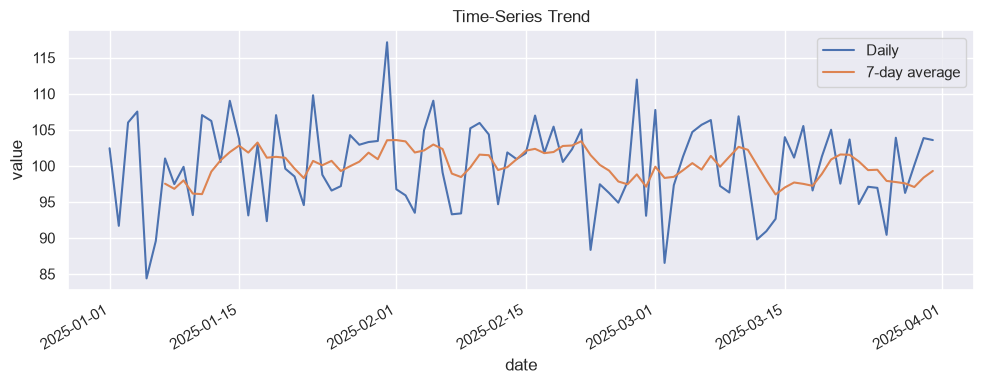

In [92]:
# Create a wide 10x4 inch figure with one axes
fig, ax = plt.subplots(figsize=(10, 4))

# Plot the raw daily series with no error bars
sns.lineplot(data=ts, x="date", y="value", errorbar=None, label="Daily")

# Plot the 7-day average with no error bars
sns.lineplot(data=ts, x="date", y="moving_avg", errorbar=None, label="7-day average")

# Set the title on the axes
ax.set_title("Time-Series Trend")

# Rotate the date labels so they do not overlap
fig.autofmt_xdate()

# Tighten the layout
fig.tight_layout()

# Display the figure
plt.show()

### Monthly aggregation

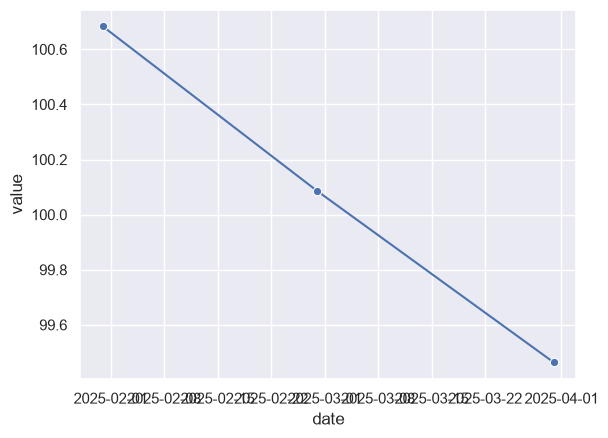

In [93]:
# Resample the time series to monthly means
monthly = ts.set_index("date").resample("ME")["value"].mean().reset_index()

# Line plot of the monthly means with circle markers, no error bars
sns.lineplot(data=monthly, x="date", y="value", marker="o", errorbar=None)

# Display the figure
plt.show()

For a single already-aggregated series, Matplotlib `ax.plot()` can be
more direct. Use Seaborn when grouping or statistical summaries are
useful.

## Plotting Statistical Uncertainty

Some Seaborn functions calculate and display estimates with uncertainty
intervals.

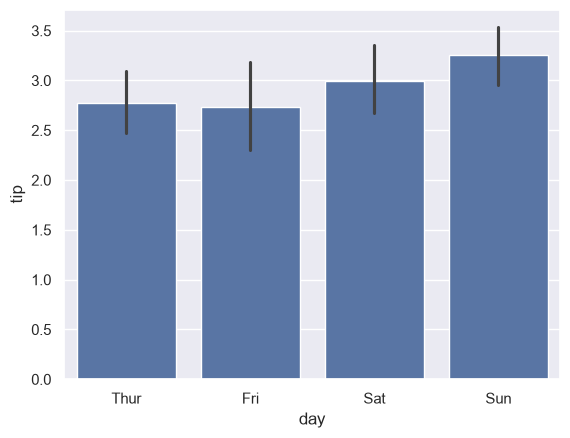

In [94]:
# Bar plot with a 95% bootstrap confidence interval
sns.barplot(data=tips, x="day", y="tip", errorbar=("ci", 95))

# Display the figure
plt.show()

Disable the interval:

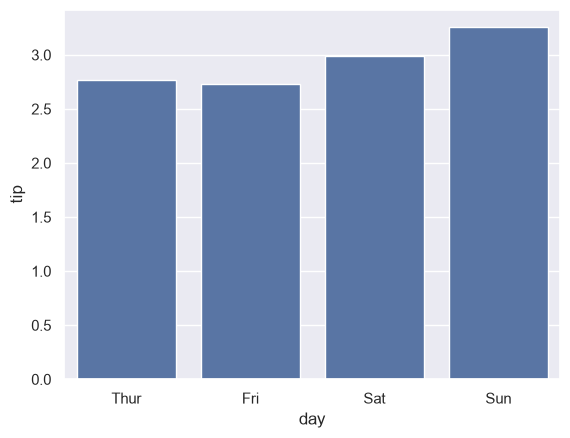

In [95]:
# Bar plot with no uncertainty interval
sns.barplot(data=tips, x="day", y="tip", errorbar=None)

# Display the figure
plt.show()

Bootstrap confidence interval:

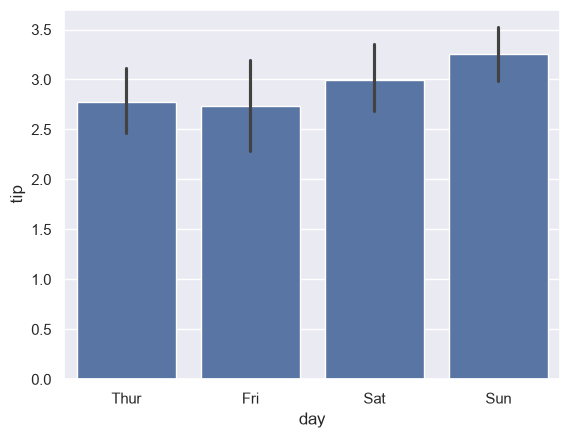

In [96]:
# Bar plot with a 95% CI computed from 1000 bootstrap resamples
sns.barplot(data=tips, x="day", y="tip", errorbar=("ci", 95), n_boot=1000)

# Display the figure
plt.show()

Other supported uncertainty options may include standard deviation or
standard error, depending on the function and Seaborn version. Consult
the function documentation for the exact accepted values.

An uncertainty interval is not automatically a range containing all
observations. Explain whether the interval represents a confidence
interval, standard error, or another quantity.

## Customizing Axes and Figures

Axes-level plot:

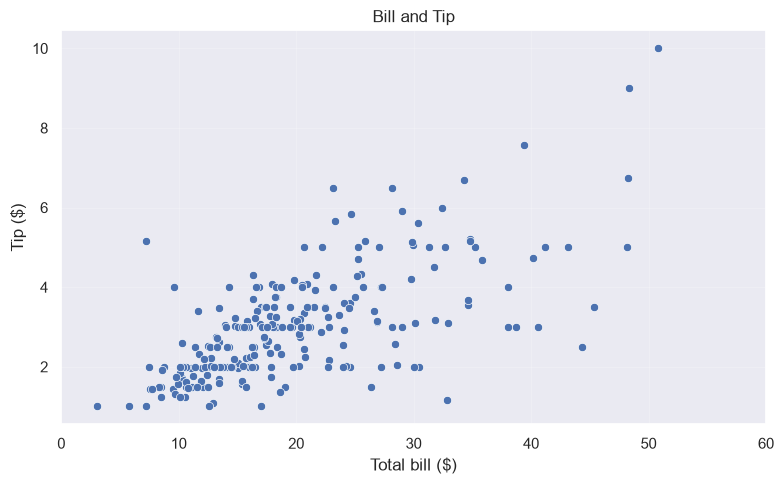

In [97]:
# Create an 8x5 inch figure with one axes
fig, ax = plt.subplots(figsize=(8, 5))

# Scatter plot drawn into the existing axes
sns.scatterplot(data=tips, x="total_bill", y="tip", ax=ax)

# Set the title
ax.set_title("Bill and Tip")

# Set the x-axis label with units
ax.set_xlabel("Total bill ($)")

# Set the y-axis label with units
ax.set_ylabel("Tip ($)")

# Limit the x-axis to 0-60
ax.set_xlim(0, 60)

# Add a light grid
ax.grid(alpha=0.2)

# Tighten the layout
fig.tight_layout()

# Display the figure
plt.show()

Figure-level plot:

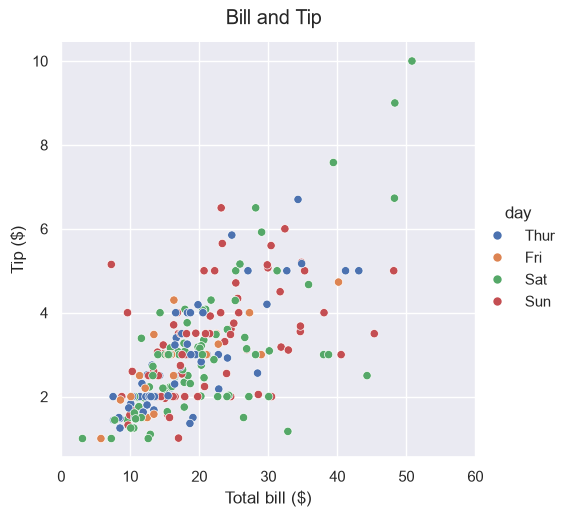

In [98]:
# Figure-level relational plot colored by day; returns a FacetGrid
g = sns.relplot(data=tips, x="total_bill", y="tip", hue="day")

# Set the axis labels with units
g.set_axis_labels("Total bill ($)", "Tip ($)")

# Set the x-axis limits on all facets
g.set(xlim=(0, 60))

# Add a figure title slightly above the plot
g.fig.suptitle("Bill and Tip", y=1.03)

# Display the figure
plt.show()

Rotate category labels:

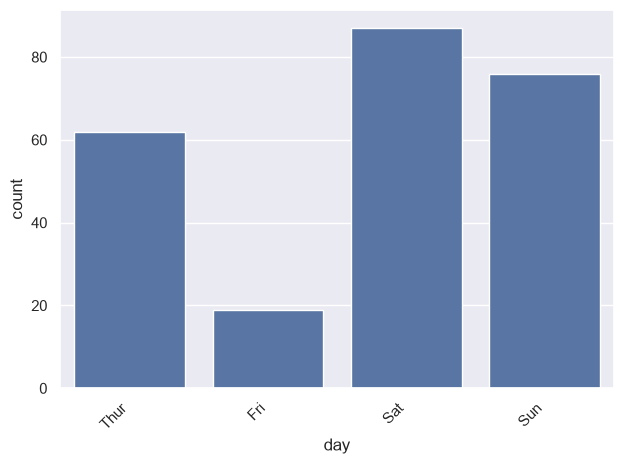

In [99]:
# Count plot with long labels
sns.countplot(data=tips, x="day")

# Rotate the x tick labels 45 degrees, right-aligned
plt.xticks(rotation=45, ha="right")

# Tighten the layout so labels are not clipped
plt.tight_layout()

# Display the figure
plt.show()

For figure-level grids, you can also iterate over axes:

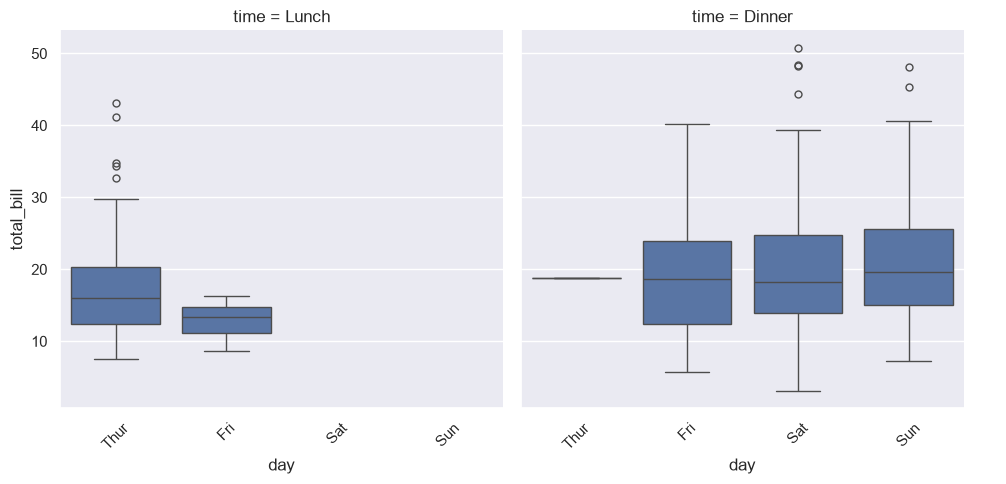

In [100]:
# Figure-level box plot faceted by time; returns a FacetGrid
g = sns.catplot(data=tips, x="day", y="total_bill", col="time", kind="box")

# Rotate the x tick labels on every facet's axes
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=45)

# Tighten the grid layout
g.tight_layout()

# Display the figure
plt.show()

## Save Seaborn Plots

Seaborn uses Matplotlib figures, so save with Matplotlib.

Saved: figures/seaborn_scatter.png


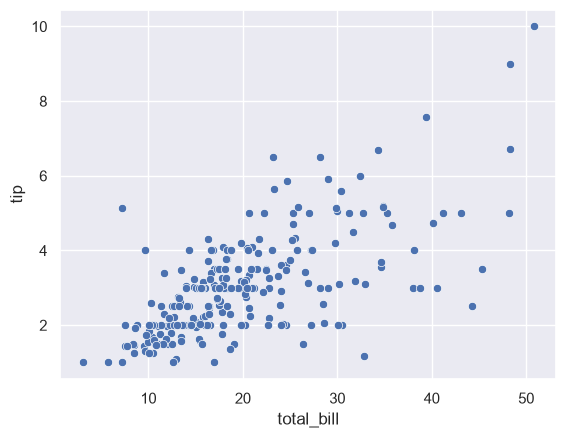

In [101]:
# Import os for working with folders
import os

# Create the "figures" folder if it does not exist (needed for saving plots)
os.makedirs("figures", exist_ok=True)

# Create a figure and one axes
fig, ax = plt.subplots()

# Scatter plot drawn into the axes
sns.scatterplot(data=tips, x="total_bill", y="tip", ax=ax)

# Save as a 300-DPI PNG, trimming extra whitespace
fig.savefig("figures/seaborn_scatter.png", dpi=300, bbox_inches="tight")

# Confirm the file was written
print("Saved: figures/seaborn_scatter.png")

Save vector formats:

Saved: figures/plot.pdf, figures/plot.svg


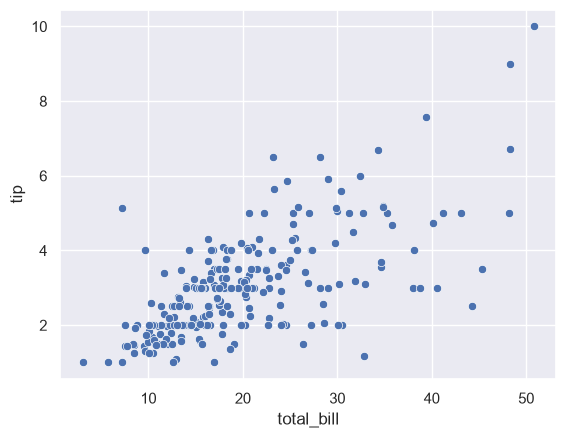

In [102]:
# Import os for working with folders
import os

# Create the "figures" folder if it does not exist (needed for saving plots)
os.makedirs("figures", exist_ok=True)

# Create a figure and one axes
fig, ax = plt.subplots()

# Scatter plot drawn into the axes
sns.scatterplot(data=tips, x="total_bill", y="tip", ax=ax)

# Save as a vector PDF (good for reports)
fig.savefig("figures/plot.pdf", bbox_inches="tight")

# Save as a scalable vector graphic
fig.savefig("figures/plot.svg", bbox_inches="tight")

# Confirm the files were written
print("Saved: figures/plot.pdf, figures/plot.svg")

For figure-level plots:

Saved: figures/pairplot.png


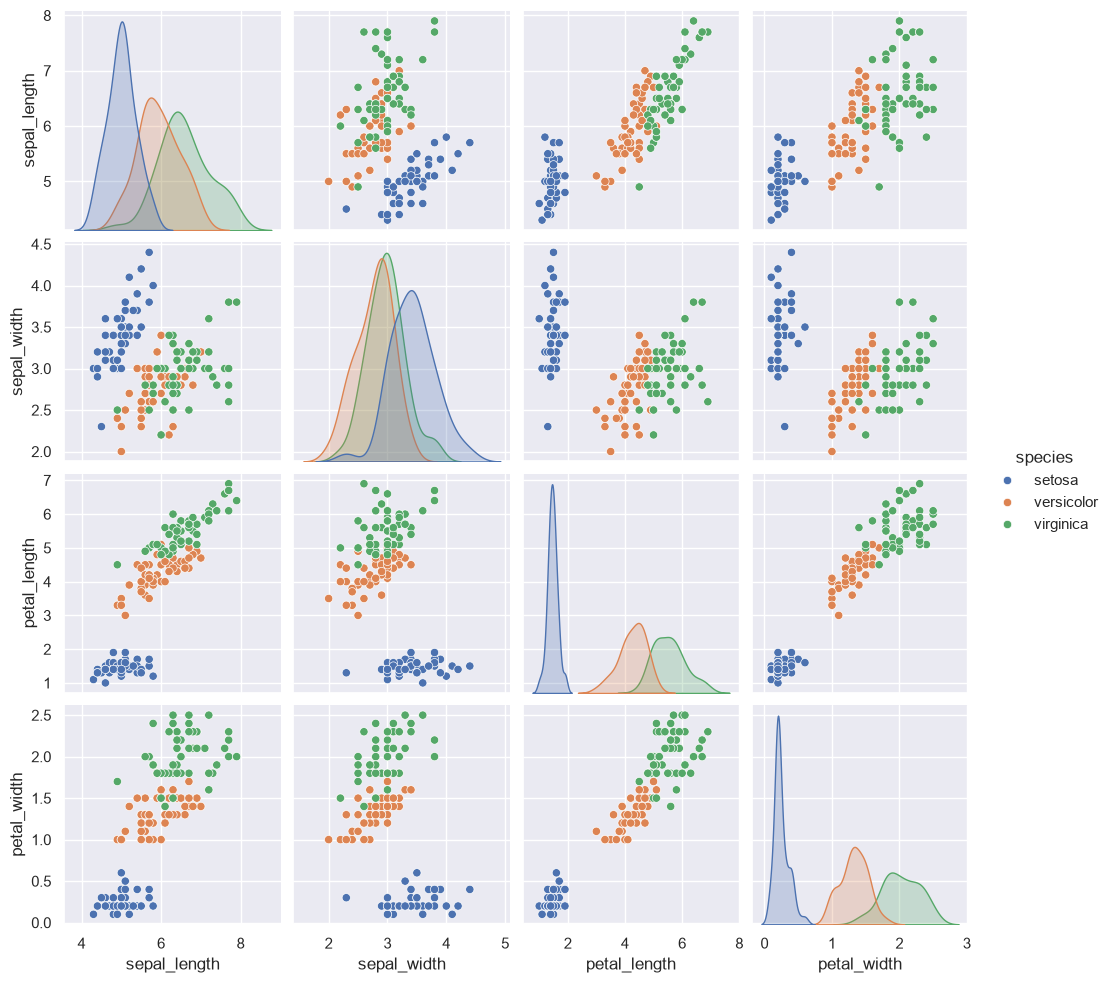

In [103]:
# Import os for working with folders
import os

# Create the "figures" folder if it does not exist (needed for saving plots)
os.makedirs("figures", exist_ok=True)

# Figure-level pair plot of the iris data; returns a PairGrid
g = sns.pairplot(iris, hue="species")

# Save the whole grid as a 300-DPI PNG
g.savefig("figures/pairplot.png", dpi=300, bbox_inches="tight")

# Confirm the file was written
print("Saved: figures/pairplot.png")

Save before closing the figure. Use PNG for common raster images and
PDF/SVG for vector-friendly reports when suitable.

## Common Seaborn Functions: Quick Reference

| Function | Purpose |
|---|---|
| `sns.scatterplot()` | Relationship between two numerical variables |
| `sns.lineplot()` | Trends and aggregated lines |
| `sns.relplot()` | Figure-level relational plots and facets |
| `sns.histplot()` | Histogram |
| `sns.kdeplot()` | Kernel density estimate |
| `sns.ecdfplot()` | Empirical cumulative distribution |
| `sns.rugplot()` | Marks individual observations |
| `sns.displot()` | Figure-level distribution plots |
| `sns.barplot()` | Estimate a statistic by category |
| `sns.countplot()` | Count observations by category |
| `sns.boxplot()` | Quartiles and potential outliers |
| `sns.violinplot()` | Distribution shape by category |
| `sns.boxenplot()` | Distribution summary for larger samples |
| `sns.stripplot()` | Individual points with jitter |
| `sns.swarmplot()` | Individual points with reduced overlap |
| `sns.pointplot()` | Summary estimates and intervals |
| `sns.catplot()` | Figure-level categorical plots |
| `sns.regplot()` | Scatter plot with regression fit |
| `sns.residplot()` | Regression residual diagnostics |
| `sns.lmplot()` | Figure-level regression and facets |
| `sns.pairplot()` | Pairwise relationships |
| `sns.PairGrid()` | Custom pairwise plot grid |
| `sns.jointplot()` | Bivariate plot with marginal distributions |
| `sns.JointGrid()` | Custom joint plot |
| `sns.heatmap()` | Matrix or correlation heatmap |
| `sns.clustermap()` | Clustered matrix visualization |
| `sns.FacetGrid()` | Custom faceted plots |

## Common Errors and Fixes

### Wrong column name

Index(['x', 'y'], dtype='str')


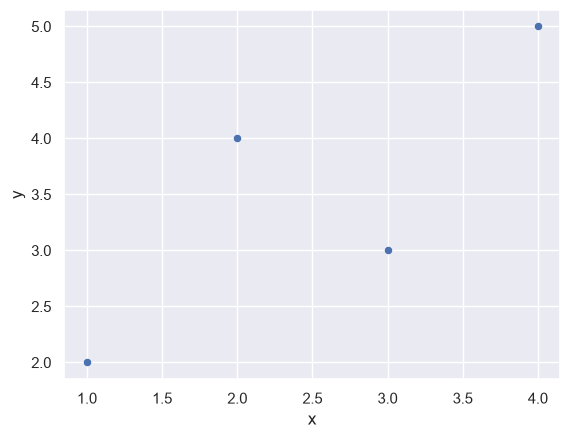

In [104]:
# Small DataFrame with columns "x" and "y"
df = pd.DataFrame({"x": [1, 2, 3, 4], "y": [2, 4, 3, 5]})

# Confirm the exact column names before plotting
print(df.columns)

# Scatter plot using the correct column names
sns.scatterplot(data=df, x="x", y="y")

# Display the figure
plt.show()

### Plot is too crowded

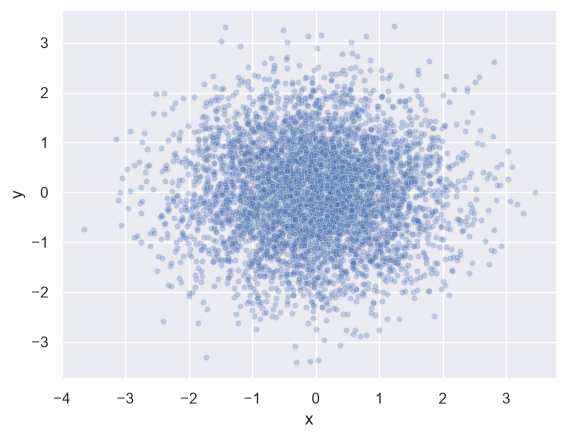

In [105]:
# Dense random data (5000 points)
df = pd.DataFrame({
    "x": np.random.default_rng(42).normal(size=5000),
    "y": np.random.default_rng(43).normal(size=5000)
})

# Scatter with transparency and small markers to reduce overplotting
sns.scatterplot(data=df, x="x", y="y", alpha=0.3, s=20)

# Display the figure
plt.show()

Consider sampling or aggregation for very large datasets.

### Categories appear in the wrong order

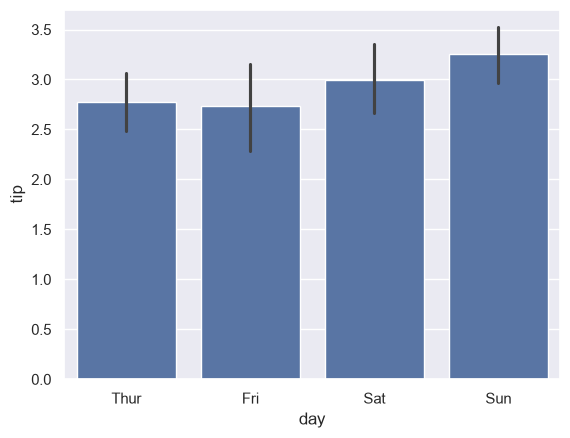

In [106]:
# Bar plot with an explicit chronological day order
sns.barplot(data=tips, x="day", y="tip",
            order=["Thur", "Fri", "Sat", "Sun"])

# Display the figure
plt.show()

### A bar plot shows averages, not counts

Use `countplot()` for row counts:

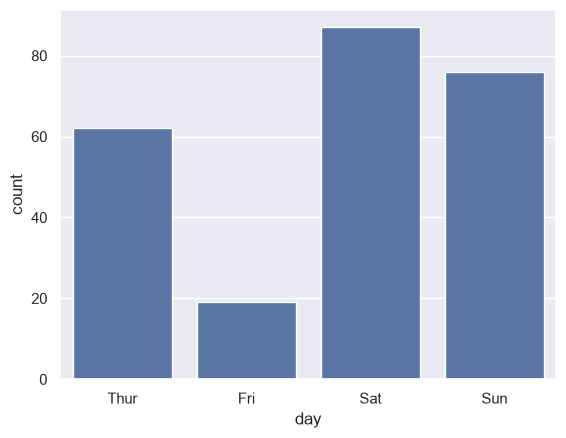

In [107]:
# Count plot: counts rows per day (not averages)
sns.countplot(data=tips, x="day")

# Display the figure
plt.show()

### Error: variable not defined

Load or create the DataFrame first, and check that each column exists:

In [108]:
# Small DataFrame
df = pd.DataFrame({"x": [1, 2, 3], "y": [2, 4, 3]})

# Preview the data
print(df.head())

# List the column names
print(df.columns.tolist())

   x  y
0  1  2
1  2  4
2  3  3
['x', 'y']


### `errorbar` parameter is not recognized

Older Seaborn releases may use the older `ci` parameter. Check the
installed version and that function's documentation. In current
releases, examples commonly use `errorbar=None` or
`errorbar=("ci", 95)`.

### FacetGrid customization fails

Figure-level functions return grid objects rather than a single Axes.
Use methods such as `g.set_axis_labels()` or access the axes with
`g.axes.flat`.

### Plot doesn't display

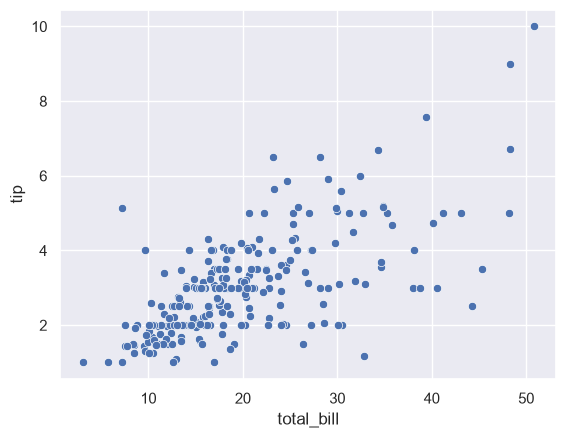

In [109]:
# Simple plot
sns.scatterplot(data=tips, x="total_bill", y="tip")

# In scripts, call plt.show() to display the figure
# In notebooks, plots are often rendered automatically
plt.show()

## Performance and Large Datasets

- Use only the variables needed for a plot.
- Reduce marker size and use transparency for dense scatter plots.
- Sample or aggregate data when that preserves the analytical question.
- Avoid swarm plots on very large datasets.
- Avoid pair plots with many columns.
- Use hexbin plots or two-dimensional histograms for dense relationships.
- Close figures in loops.

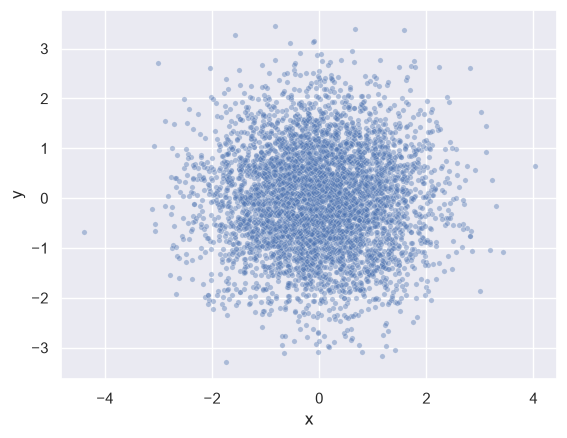

In [110]:
# Large DataFrame with the columns needed for the plots
df = pd.DataFrame({
    "x": np.random.default_rng(42).normal(size=20_000),
    "y": np.random.default_rng(43).normal(size=20_000),
    "category": np.random.default_rng(44).choice(["A", "B", "C"], size=20_000),
    "value": np.random.default_rng(45).normal(size=20_000)
})

# Random sample of up to 5000 rows
plot_df = df.sample(n=min(5000, len(df)), random_state=42)

# Scatter the sample with transparency and small markers
sns.scatterplot(data=plot_df, x="x", y="y", alpha=0.4, s=15)

# Display the figure
plt.show()

For dense data, use Matplotlib's hexbin:

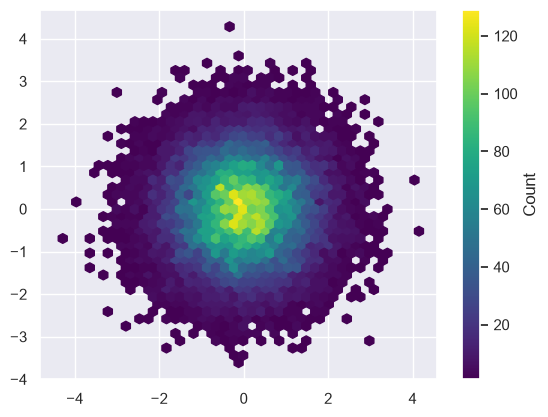

In [111]:
# Create a figure and one axes
fig, ax = plt.subplots()

# Hexbin density plot of the large DataFrame
hb = ax.hexbin(df["x"], df["y"], gridsize=40, mincnt=1, cmap="viridis")

# Add a colorbar showing the count per hexagon
fig.colorbar(hb, ax=ax, label="Count")

# Display the figure
plt.show()

Close figures created in loops:

In [112]:
# Import os for working with folders
import os

# Create the "figures" folder if it does not exist (needed for saving plots)
os.makedirs("figures", exist_ok=True)

# Loop over each category group
for category, group in df.groupby("category"):

    # Create a new figure and axes each iteration
    fig, ax = plt.subplots()

    # Histogram of the group's values
    sns.histplot(data=group, x="value", ax=ax)

    # Save the figure with the category in the filename
    fig.savefig(f"figures/{category}_hist.png", dpi=200, bbox_inches="tight")

    # Close the figure to release its memory
    plt.close(fig)

# Confirm the loop finished
print("Saved one histogram per category and closed all figures.")

Saved one histogram per category and closed all figures.


## Practical Data Science Examples

### Explore the tips dataset

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
        total_bill         tip   sex smoker  day    time        size
count   244.000000  244.000000   244    244  244     244  244.000000
unique         NaN         NaN     2      2    4       2         NaN
top            NaN         NaN  Male     No  Sat  Dinner         NaN
freq           NaN         NaN   157    151   87     176         NaN
mean     19.785943    2.998279   NaN    NaN  NaN     NaN    2.569672
std       8.902412    1.383638   NaN    NaN  NaN     NaN    0.951100
min       3.070000    1.000000   NaN    NaN  NaN     NaN    1.000000
25%      13.347500    2.000000   NaN    NaN  NaN     NaN    2.000000
50%      17.795000    2.900000   NaN    NaN  NaN     Na

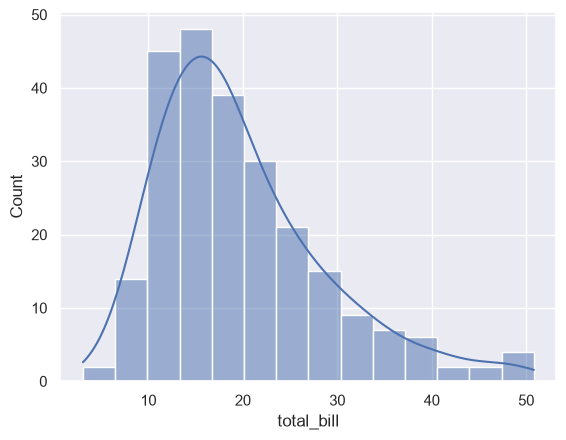

In [113]:
# Load the tips dataset
tips = sns.load_dataset("tips")

# Check data and summary statistics
print(tips.head())
print(tips.describe(include="all"))

# Distribution of total bills with a KDE overlay
sns.histplot(data=tips, x="total_bill", kde=True)

# Display the figure
plt.show()

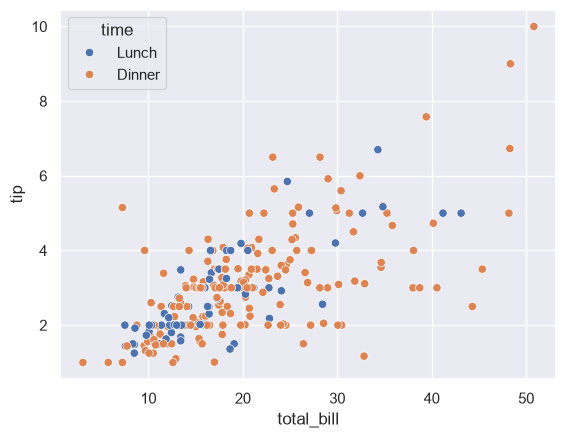

In [114]:
# Bill and tip relationship, colored by time of day
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time")

# Display the figure
plt.show()

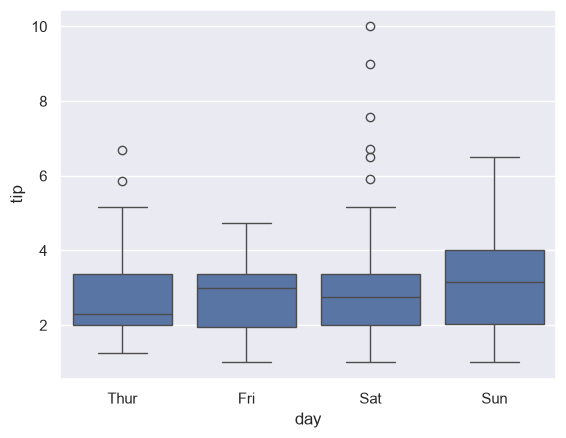

In [115]:
# Tip distribution by day
sns.boxplot(data=tips, x="day", y="tip")

# Display the figure
plt.show()

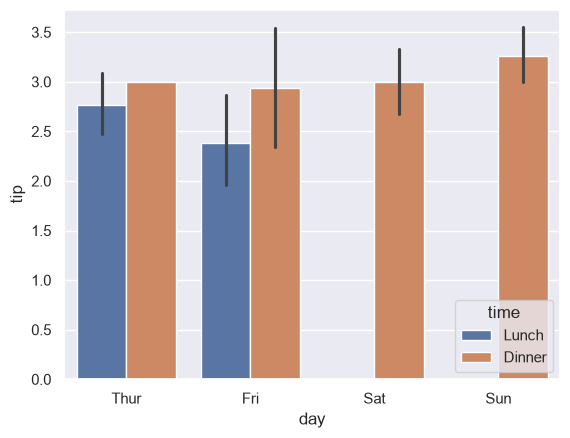

In [116]:
# Average tip by day and time
sns.barplot(data=tips, x="day", y="tip", hue="time")

# Display the figure
plt.show()

### Explore the Iris dataset

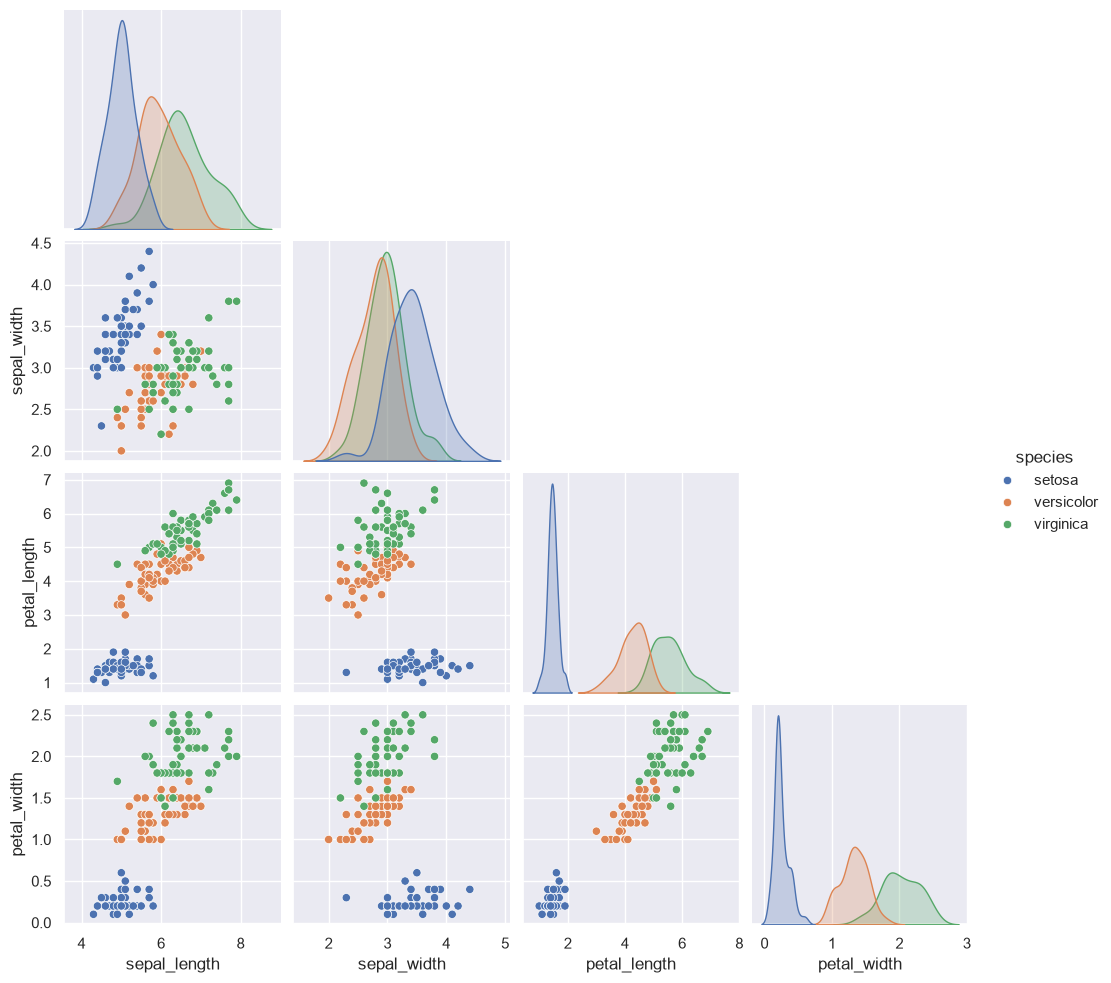

In [117]:
# Load the iris dataset
iris = sns.load_dataset("iris")

# Compare species across feature pairs (lower triangle only)
sns.pairplot(iris, hue="species", corner=True)

# Display the figure
plt.show()

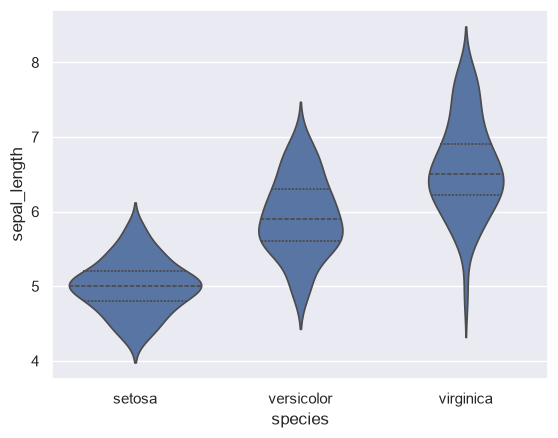

In [118]:
# Compare sepal length by species with quartile lines
sns.violinplot(data=iris, x="species", y="sepal_length", inner="quart")

# Display the figure
plt.show()

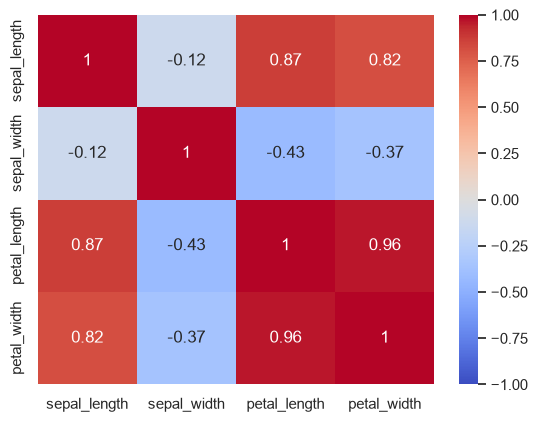

In [119]:
# Correlation matrix of the numeric iris features
corr = iris.select_dtypes(include="number").corr()

# Correlation heatmap centered at 0
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)

# Display the figure
plt.show()

### Build a small EDA dashboard

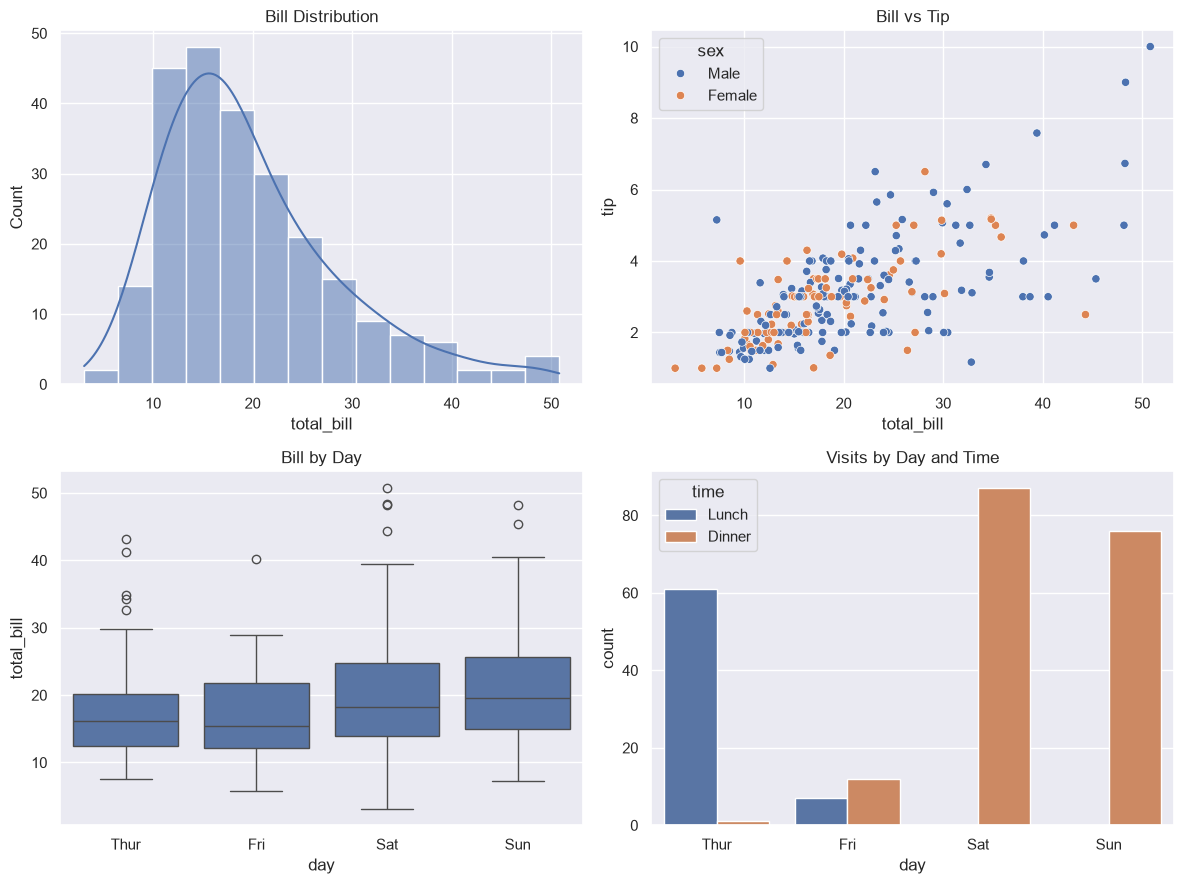

In [120]:
# Load the tips dataset
tips = sns.load_dataset("tips")

# Create a 2x2 subplot grid, 12x9 inches
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Top-left: bill distribution with KDE
sns.histplot(data=tips, x="total_bill", kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Bill Distribution")

# Top-right: bill vs tip, colored by sex
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="sex", ax=axes[0, 1])
axes[0, 1].set_title("Bill vs Tip")

# Bottom-left: bill by day
sns.boxplot(data=tips, x="day", y="total_bill", ax=axes[1, 0])
axes[1, 0].set_title("Bill by Day")

# Bottom-right: visits by day and time
sns.countplot(data=tips, x="day", hue="time", ax=axes[1, 1])
axes[1, 1].set_title("Visits by Day and Time")

# Tighten the layout
fig.tight_layout()

# Display the figure
plt.show()

## Plot Selection Guide

| Analytical question | Good starting plot |
|---|---|
| How are two numerical variables related? | `scatterplot()` |
| How does a variable change over time? | `lineplot()` |
| What is the distribution of a numeric variable? | `histplot()`, `kdeplot()`, `ecdfplot()` |
| How do numerical distributions compare across groups? | `boxplot()`, `violinplot()`, `boxenplot()` |
| How many rows are in each category? | `countplot()` |
| What is the mean or another estimate by category? | `barplot()`, `pointplot()` |
| How do several numeric variables relate? | `pairplot()` |
| What is the relationship plus each variable's distribution? | `jointplot()` |
| How are correlations arranged? | `heatmap()` |
| How does a relationship differ across groups? | `relplot()` with `hue`, `col`, or `row` |
| Does a regression fit show patterns in errors? | `residplot()` |
| How do groups differ across multiple panels? | `catplot()`, `FacetGrid()` |

## Practice Exercises

1. Load the `tips` dataset and inspect its columns and data types.
2. Plot the distribution of `total_bill` using a histogram and KDE.
3. Compare `tip` against `total_bill` using `hue="day"`.
4. Compare total bills across days with a box plot and violin plot.
5. Use `countplot()` to compare the number of observations by day and time.
6. Create a correlation heatmap from numeric columns in a dataset.
7. Use `pairplot()` on the Iris dataset and color by species.
8. Create a faceted scatter plot split by `sex` or `time`.
9. Fit a regression line and inspect the residual plot.
10. Build a 2 × 2 exploratory data analysis dashboard.
11. Save one figure as a 300-DPI PNG and another as PDF.
12. Write three observations and distinguish association from causation.

## Data Visualization Checklist

- [ ] The plot matches the question being investigated.
- [ ] The title, axes, units, and legend are clear.
- [ ] Categories are ordered intentionally.
- [ ] Color mappings have a clear meaning.
- [ ] The scale does not distort interpretation.
- [ ] Missing values and outliers are handled transparently.
- [ ] Uncertainty intervals are understood and described correctly.
- [ ] The plot is readable and not overcrowded.
- [ ] The figure is saved in a suitable format and resolution.
- [ ] Conclusions do not claim causation from correlation alone.

## Best Practices

- Prefer long-form DataFrames for clear `x`, `y`, `hue`, and facet mappings.
- Use axes-level functions for individual plots and figure-level functions for faceting.
- Use `barplot()` for estimated statistics and `countplot()` for counts.
- Remember that Seaborn may aggregate repeated observations and display uncertainty intervals.
- Use Matplotlib methods for fine-grained labels, layout, and export.
- Start with a small set of relevant variables rather than plotting every column.
- Treat visual patterns as evidence to investigate, not proof by themselves.